# Vertical cross sections

### Why this notebook matters

This notebook demonstrates vertical cross-section diagnostics of zonal wind, temperature, and vertical velocity from high-resolution 3D pressure-level output, comparing climatology against projected trends.

**Purpose** - Compute atmospheric vertical cross-sections (zonal wind, temperature, vertical velocity) and their 2020-2039 trends from high-resolution 3D pressure-level output, and compare climatologies between the first and last 5 years of the projection.

**Required input data** - 3D pressure-level variables (`t`, `u`, `w`) NetCDF files on the HEALPix grid under `{PROJ2559_DIR}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - Latitude-pressure cross-sections and trend maps for zonal wind, temperature, and vertical velocity.

## Key techniques demonstrated

- Vertical cross-section extraction from 3D pressure-level data
- Climatology vs trend comparison
- HEALPix handling with healpy
- Cartopy + cmocean mapping

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set this path to your own data copy before running:
#
# PROJ2559_DIR : root of the projection experiment (2020-2039)
#                (subfolders: pl_dy/ana_var_*/ for 3D pressure-level diagnostics)

PROJ2559_DIR = "/path/to/proj2559"  # <-- EDIT before running

## Load packages

In [1]:
import os
import numpy as np
import xarray as xr
import healpy as hp
import cmocean as cmo
import matplotlib.cm as cm
import matplotlib.pylab as plt

## Zonal wind 'u'

### Check data : 1 timestep

In [2]:
# @ Levante
pathpl_dy_u = f"{PROJ2559_DIR}/pl_dy/tco2559_proj/0001_pl_u_healpix_hourly_2034.grb"
data_pl_dy_u = xr.open_dataset(pathpl_dy_u, engine="cfgrib")
data_pl_dy_u

<xarray.Dataset>
Dimensions:        (time: 365, isobaricInhPa: 25, values: 196608)
Coordinates:
  * time           (time) datetime64[ns] 2034-01-01 2034-01-02 ... 2034-12-31
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
    valid_time     (time) datetime64[ns] ...
Dimensions without coordinates: values
Data variables:
    u              (time, isobaricInhPa, values) float32 ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          1003
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-04-30T09:54 GRIB to CDM+CF via cfgrib-0.9.1...

/tmp/ipykernel_915570/282075252.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


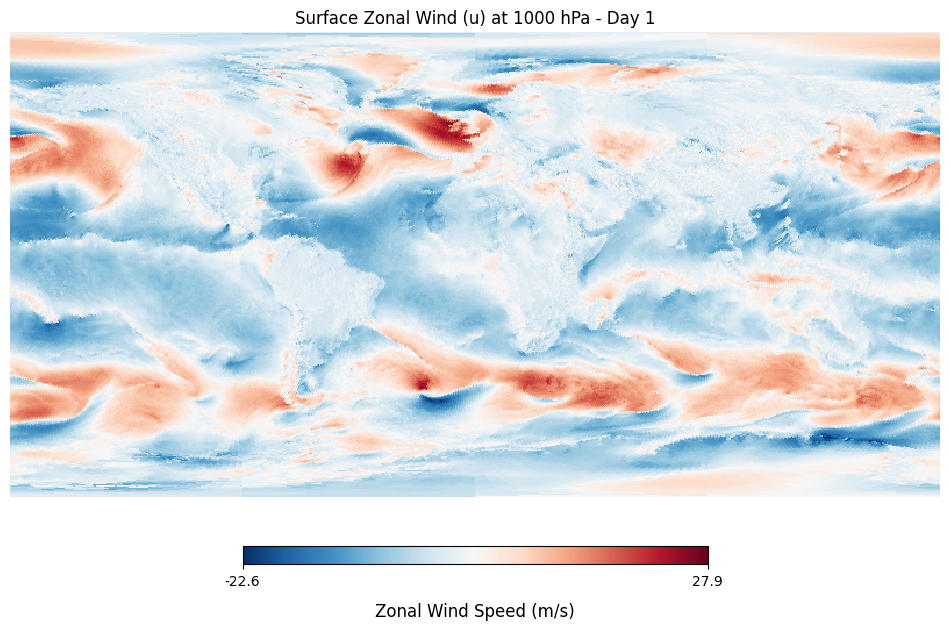

In [3]:
# Select surface level (1000 hPa) and first timestep
u_surface = data_pl_dy_u.u.isel(time=0, isobaricInhPa=0)  # Index 0 = 1000 hPa

# Convert to numpy array
u_surface_map = u_surface.values

# Plot settings
plt.figure(figsize=(12, 8))

# Plot the map using Healpy's cartview (just the variable, no overlays)
hp.cartview(
    u_surface_map,
    flip="geo",          # Match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING)
    lonra=[-180, 180],   # Full longitude range
    latra=[-90, 90],     # Full latitude range
    title="Surface Zonal Wind (u) at 1000 hPa - Day 1",
    min=None,            # Auto color scale
    max=None,
    cmap="RdBu_r",       # Red-Blue for winds (negative=easterly, positive=westerly)
    badcolor="gray",     # Missing data color
    hold=True,
)

# Customize colorbar only
cbar = plt.gcf().axes[-1]
cbar.set_xlabel("Zonal Wind Speed (m/s)", fontsize=12, labelpad=10)

# Adjust layout
plt.tight_layout()
plt.show()

In [5]:
#  Interpolate HEALPix Data to Regular Grid

import numpy as np
import healpy as hp

# Select surface level (1000 hPa) and first timestep
u_surface = data_pl_dy_u.u.isel(time=0, isobaricInhPa=0).values  # Directly get values

# Replace NaN values
u_surface = np.nan_to_num(u_surface, nan=0)

# Create regular lat/lon grid (360x180)
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                     np.linspace(-90, 90, 180))

# Interpolate HEALPix â†’ Regular grid
grid_u = np.zeros_like(grid_lat)
for i in range(grid_lon.shape[0]):
    for j in range(grid_lon.shape[1]):
        grid_u[i,j] = hp.get_interp_val(u_surface, 
                                      grid_lon[i,j], grid_lat[i,j], 
                                      lonlat=True, nest=True)

print(f"Interpolated wind min: {grid_u.min():.1f} m/s, max: {grid_u.max():.1f} m/s")

Interpolated wind min: -21.8 m/s, max: 25.7 m/s


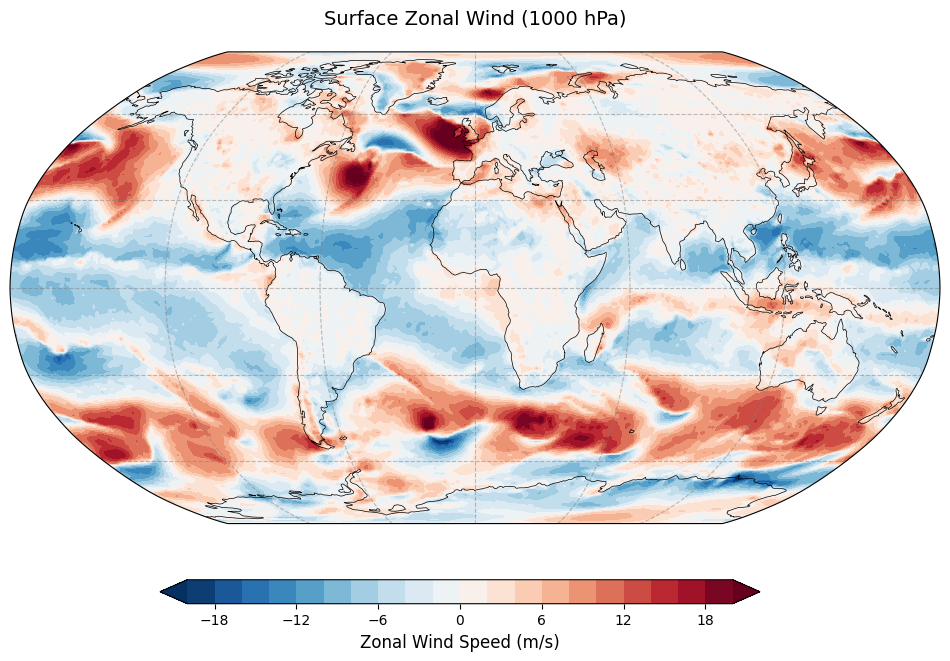

In [7]:
## Plot Robinson Projection

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection=ccrs.Robinson())

# Symmetric colormap for winds (negative=easterly, positive=westerly)
levels = np.linspace(-20, 20, 21)  # Adjust range based on your data
cmap = plt.cm.RdBu_r  # Red-Blue reversed

cf = ax.contourf(grid_lon, grid_lat, grid_u, 
                levels=levels, cmap=cmap,
                transform=ccrs.PlateCarree(),
                extend='both')

ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)
plt.title("Surface Zonal Wind (1000 hPa)", fontsize=14, pad=20)

# Add horizontal colorbar at bottom
cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax, orientation='horizontal')
cbar.set_label("Zonal Wind Speed (m/s)", fontsize=12)
plt.show()

### Monthly means

In [3]:
import os
import xarray as xr

# Define paths (adjust to your zonal wind data)
base_path = f"{PROJ2559_DIR}/pl_dy/tco2559_proj/0001_pl_u_healpix_hourly_"
years = range(2021, 2040)  # 2020â€“2039
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_ums/"  # Output directory

# # Create output directory if missing
# os.makedirs(output_dir, exist_ok=True)

In [16]:
# Create monthly mean files 

# for year in years:
#     file_path = f"{base_path}{year}.grb"
#     print(f"Processing {year}...")
    
#     # Open dataset and preserve all pressure levels
#     with xr.open_dataset(file_path, engine="cfgrib", chunks={"time": 1000}) as ds:
#         # Group by month and pressure level, then compute mean
#         monthly_means = ds.u.groupby("time.month").mean(dim="time").compute()
        
#         # Save to NetCDF (retains all 25 levels)
#         output_file = f"{output_dir}monthly_mean_u_all_levels_{year}.nc"
#         monthly_means.to_dataset(name="u").to_netcdf(output_file)

Processing 2021...
Processing 2022...
Processing 2023...
Processing 2024...
Processing 2025...
Processing 2026...
Processing 2027...
Processing 2028...
Processing 2029...
Processing 2030...
Processing 2032...
Processing 2033...
Processing 2034...
Processing 2035...
Processing 2036...
Processing 2037...
Processing 2038...
Processing 2039...


In [4]:
# Check one output file
test = xr.open_dataset(f"{output_dir}monthly_mean_u_all_levels_2020.nc")
print(test)

# Expected output:
# <xarray.Dataset>
# Dimensions:  (month: 12, values: 196608)
# Coordinates:
#   * month    (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
# Data variables:
#     u        (month, values) float32 ...

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608, month: 12)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
  * month          (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
Dimensions without coordinates: values
Data variables:
    u              (month, isobaricInhPa, values) float32 ...


### Annual means

In [13]:
# Setup & Load Monthly Means

import xarray as xr
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_ums/"

# Load all monthly files (2020-2039)
datasets = []
for year in range(2020, 2040):
    file_path = f"{output_dir}monthly_mean_u_all_levels_{year}.nc"
    ds = xr.open_dataset(file_path)
    
    # Remove existing time coordinate if present
    if 'time' in ds.coords:
        ds = ds.drop_vars('time')
        
    # Add corrected time coordinates
    time = xr.cftime_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=("month", time))
    
    datasets.append(ds)

In [15]:
#print(datasets)

In [16]:
# Corrected Cell 2: Concatenate along time dimension (simple and robust)
ds = xr.concat(datasets, dim="month")  # 'month' is the common dimension

# Reassign time coordinate properly (all months from 2020-2039)
time = xr.cftime_range(start="2020-01-31", end="2039-12-31", freq="M")
ds = ds.assign_coords(time=("month", time))

# Verify
print(ds)
# Output should show:
# Dimensions: (month: 240, isobaricInhPa: 25, values: 196608)
# Coordinates: time (month), isobaricInhPa, latitude, longitude

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608, month: 240)
Coordinates:
    step           timedelta64[ns] 00:00:00
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 0.2984 0.5968 0.5968 ... -0.5968 -0.2984
    longitude      (values) float64 45.0 45.35 44.65 45.0 ... 315.4 314.6 315.0
  * month          (month) int64 1 2 3 4 5 6 7 8 9 10 ... 3 4 5 6 7 8 9 10 11 12
    time           (month) object 2020-01-31 00:00:00 ... 2039-12-31 00:00:00
Dimensions without coordinates: values
Data variables:
    u              (month, isobaricInhPa, values) float32 -9.391 ... 19.37


In [17]:
## Calculate Annual Means 
# Group by year and compute mean - no need to modify time coordinates further
annual_means = ds.u.groupby("time.year").mean(dim="month")

# Verify structure
print(annual_means)
# Expected:
# <xarray.DataArray 'u' (year: 20, isobaricInhPa: 25, values: 196608)>

<xarray.DataArray 'u' (year: 20, isobaricInhPa: 25, values: 196608)>
array([[[ -3.511342  ,  -3.2941163 ,  -3.5116832 , ...,  -6.8354554 ,
          -6.727923  ,  -6.987394  ],
        [ -3.7310946 ,  -3.4922476 ,  -3.7530422 , ...,  -7.5493317 ,
          -7.263414  ,  -7.62825   ],
        [ -3.8475275 ,  -3.6179764 ,  -3.9623315 , ...,  -7.673144  ,
          -7.446881  ,  -7.7740054 ],
        ...,
        [ -3.170821  ,  -3.349415  ,  -3.297082  , ...,  -6.0706635 ,
          -6.103767  ,  -6.148197  ],
        [  3.164828  ,   3.0705483 ,   3.0041103 , ...,   0.4017941 ,
           0.49557304,   0.23293877],
        [ 12.713448  ,  12.813831  ,  12.9686165 , ...,   1.6038872 ,
           1.5043024 ,   1.8533455 ]],

       [[ -4.267572  ,  -4.00297   ,  -4.305123  , ...,  -7.276521  ,
          -7.1495667 ,  -7.3644524 ],
        [ -4.524214  ,  -4.2369256 ,  -4.584786  , ...,  -7.886881  ,
          -7.6225486 ,  -7.8654265 ],
        [ -4.699946  ,  -4.4006915 ,  -4.7777815 , .

In [18]:
# Save Annual Means

for year in annual_means.year.values:
    annual_means.sel(year=year).to_dataset(name="u").to_netcdf(
        f"{output_dir}annual_mean_u_all_levels_{year}.nc"
    )

In [19]:
# Long-Term Climatology

# Directly compute 20-year average
long_term_mean = annual_means.mean(dim="year")

# Save (one file with all levels)
long_term_mean.to_dataset(name="u").to_netcdf(
    f"{output_dir}climatology_u_all_levels_2020-2039.nc"
)

In [20]:
# Check one annual file
test = xr.open_dataset(f"{output_dir}annual_mean_u_all_levels_2025.nc")
print(test.isobaricInhPa.values)  # Should show all 25 levels

[1000.  975.  950.  925.  900.  875.  850.  800.  750.  700.  600.  500.
  400.  300.  250.  200.  150.  100.   70.   50.   30.   20.   10.    5.
    1.]


### Plot: Climatology

In [2]:
# Load & Interpolate U-Velocity

import xarray as xr
import numpy as np
import healpy as hp

# Load u-velocity climatology
ds_u = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_ums/climatology_u_all_levels_2020-2039.nc")

# Select 4 key pressure levels (hPa)
levels = [1000, 500, 250, 50]  # Surface to stratosphere

# Create regular lat/lon grid (360x180)
lon_grid, lat_grid = np.meshgrid(np.linspace(-180, 180, 360), 
                              np.linspace(-90, 90, 180))

# Interpolate HEALPix to regular grid for each level
grid_u = {}
for level in levels:
    u_data = ds_u.u.sel(isobaricInhPa=level, method="nearest").values
    grid_u[level] = hp.get_interp_val(np.nan_to_num(u_data, nan=0),
                                    lon_grid, lat_grid,
                                    lonlat=True, nest=True)
    
    print(f"{level} hPa: Min={grid_u[level].min():.1f} m/s, Max={grid_u[level].max():.1f} m/s")

1000 hPa: Min=-12.3 m/s, Max=11.2 m/s
500 hPa: Min=-6.4 m/s, Max=27.4 m/s
250 hPa: Min=-9.9 m/s, Max=40.7 m/s
50 hPa: Min=-6.9 m/s, Max=38.8 m/s


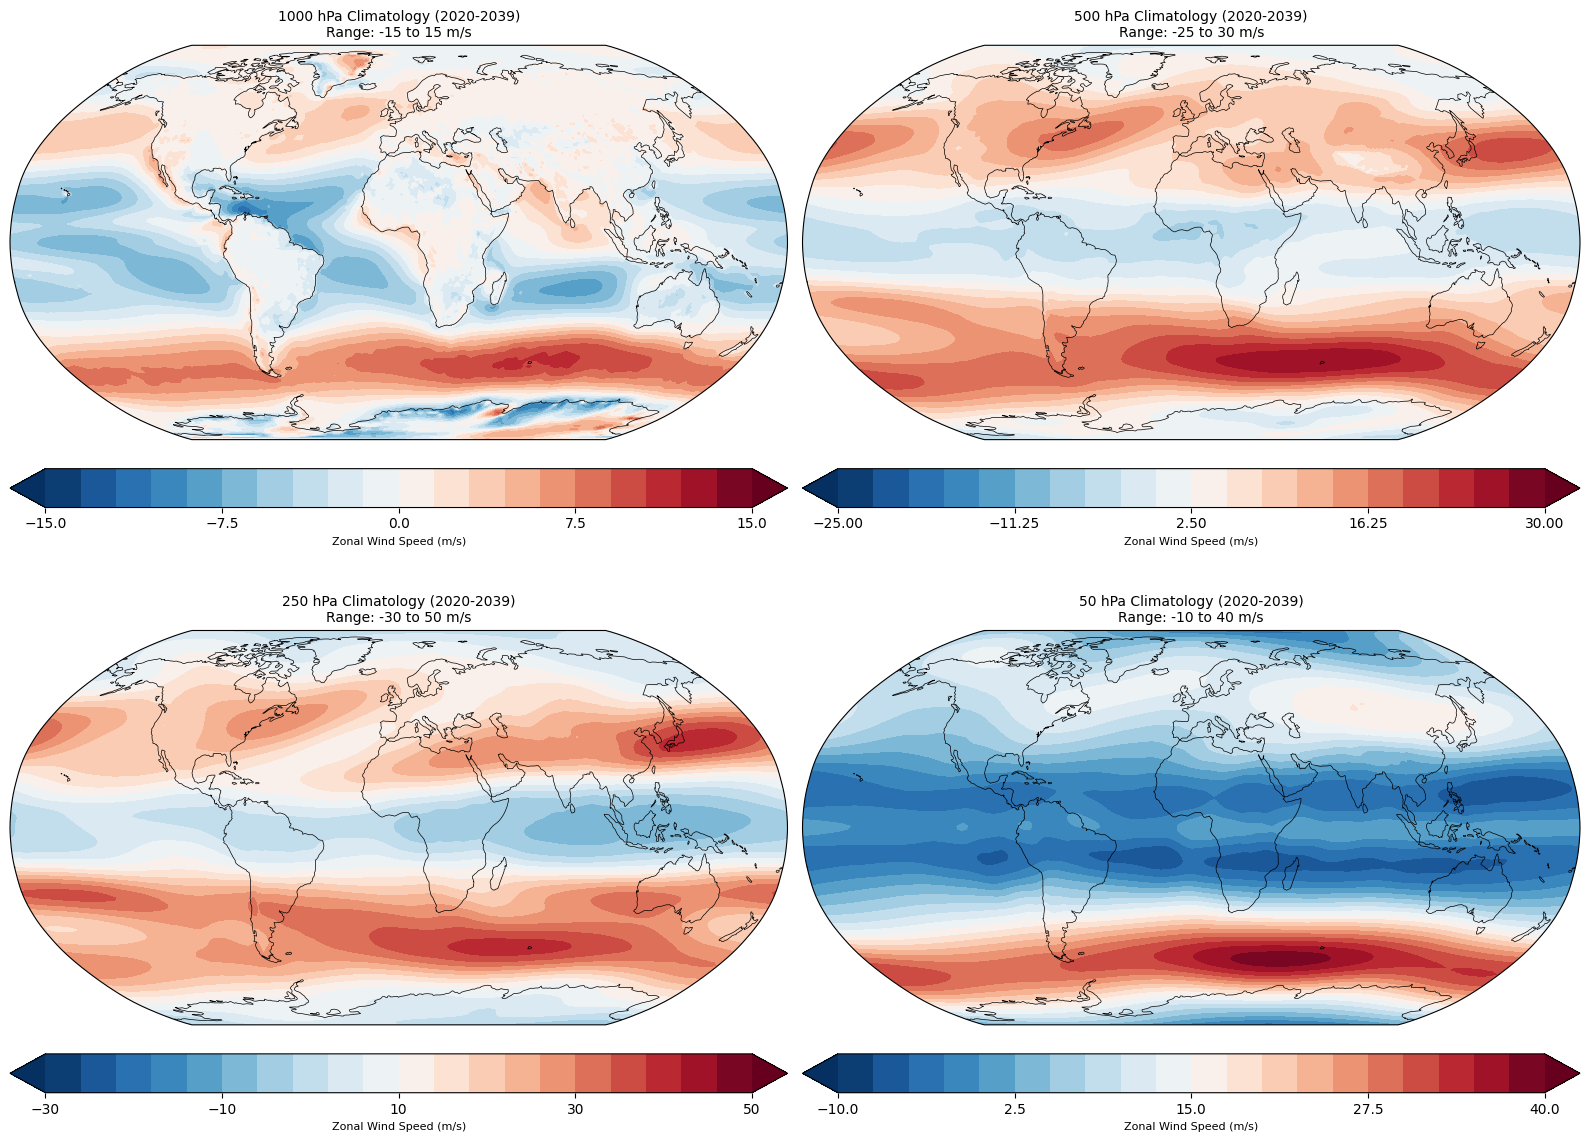

In [3]:
# Plot U-Velocity with Level-Specific Ranges

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Define level-specific wind ranges (m/s)
level_ranges = {
    1000: (-15, 15),   # Surface: easterlies/westerlies
    500: (-25, 30),    # Mid-troposphere (stronger jets)
    250: (-30, 50),    # Upper-troposphere (jet streams)
    50: (-10, 40)      # Stratosphere (weaker winds)
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12),
                        subplot_kw={'projection': ccrs.Robinson()})
axes = axes.flatten()

for ax, level in zip(axes, levels):
    # Get data and range for current level
    data = grid_u[level]
    vmin, vmax = level_ranges[level]
    
    # Plot with RdBu_r colormap (red=westerlies, blue=easterlies)
    cf = ax.contourf(lon_grid, lat_grid, data,
                    levels=np.linspace(vmin, vmax, 21),
                    cmap='RdBu_r',
                    transform=ccrs.PlateCarree(),
                    extend='both')
    
    # Add map features
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.set_title(f"{level} hPa Climatology (2020-2039)\nRange: {vmin} to {vmax} m/s", 
                fontsize=10)
    
    # Add colorbar
    cbar = fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05)
    cbar.set_label("Zonal Wind Speed (m/s)", fontsize=8)
    cbar.set_ticks(np.linspace(vmin, vmax, 5))  # 5 major ticks

plt.tight_layout()
plt.show()

In [4]:
import xarray as xr
import numpy as np
import healpy as hp

# Load u-velocity climatology
ds_u = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_ums/climatology_u_all_levels_2020-2039.nc")

# Select 4 key pressure levels (hPa)
levels = [1000, 500, 250, 50]  # Surface to stratosphere

# Create regular lat/lon grid (360x180)
lon_grid, lat_grid = np.meshgrid(
    np.linspace(-180, 180, 360),
    np.linspace(-90, 90, 180)
)

# Convert to HEALPix theta/phi (in radians)
# theta: colatitude [0, pi], phi: longitude [0, 2pi]
theta = np.radians(90 - lat_grid)  # colatitude
phi = np.radians((lon_grid + 360) % 360)  # ensure range [0, 2pi]

# Interpolate for each level
grid_u = {}
for level in levels:
    u_data = ds_u.u.sel(isobaricInhPa=level, method="nearest").values

    # Replace NaNs with zeros or better: interpolate masked array if needed
    u_data_clean = np.nan_to_num(u_data, nan=0)

    # Determine nside from length of u_data
    npix = len(u_data_clean)
    nside = hp.npix2nside(npix)

    # Interpolate using healpy's get_interp_val
    # NOTE: assumes nested ordering. Set nest=False if it's ring-ordered.
    interp_values = hp.get_interp_val(u_data_clean, theta, phi, nest=True)

    grid_u[level] = interp_values

    print(f"{level} hPa: Min={interp_values.min():.1f} m/s, Max={interp_values.max():.1f} m/s")

1000 hPa: Min=-12.3 m/s, Max=11.2 m/s
500 hPa: Min=-6.4 m/s, Max=27.4 m/s
250 hPa: Min=-9.9 m/s, Max=40.7 m/s
50 hPa: Min=-6.9 m/s, Max=38.8 m/s


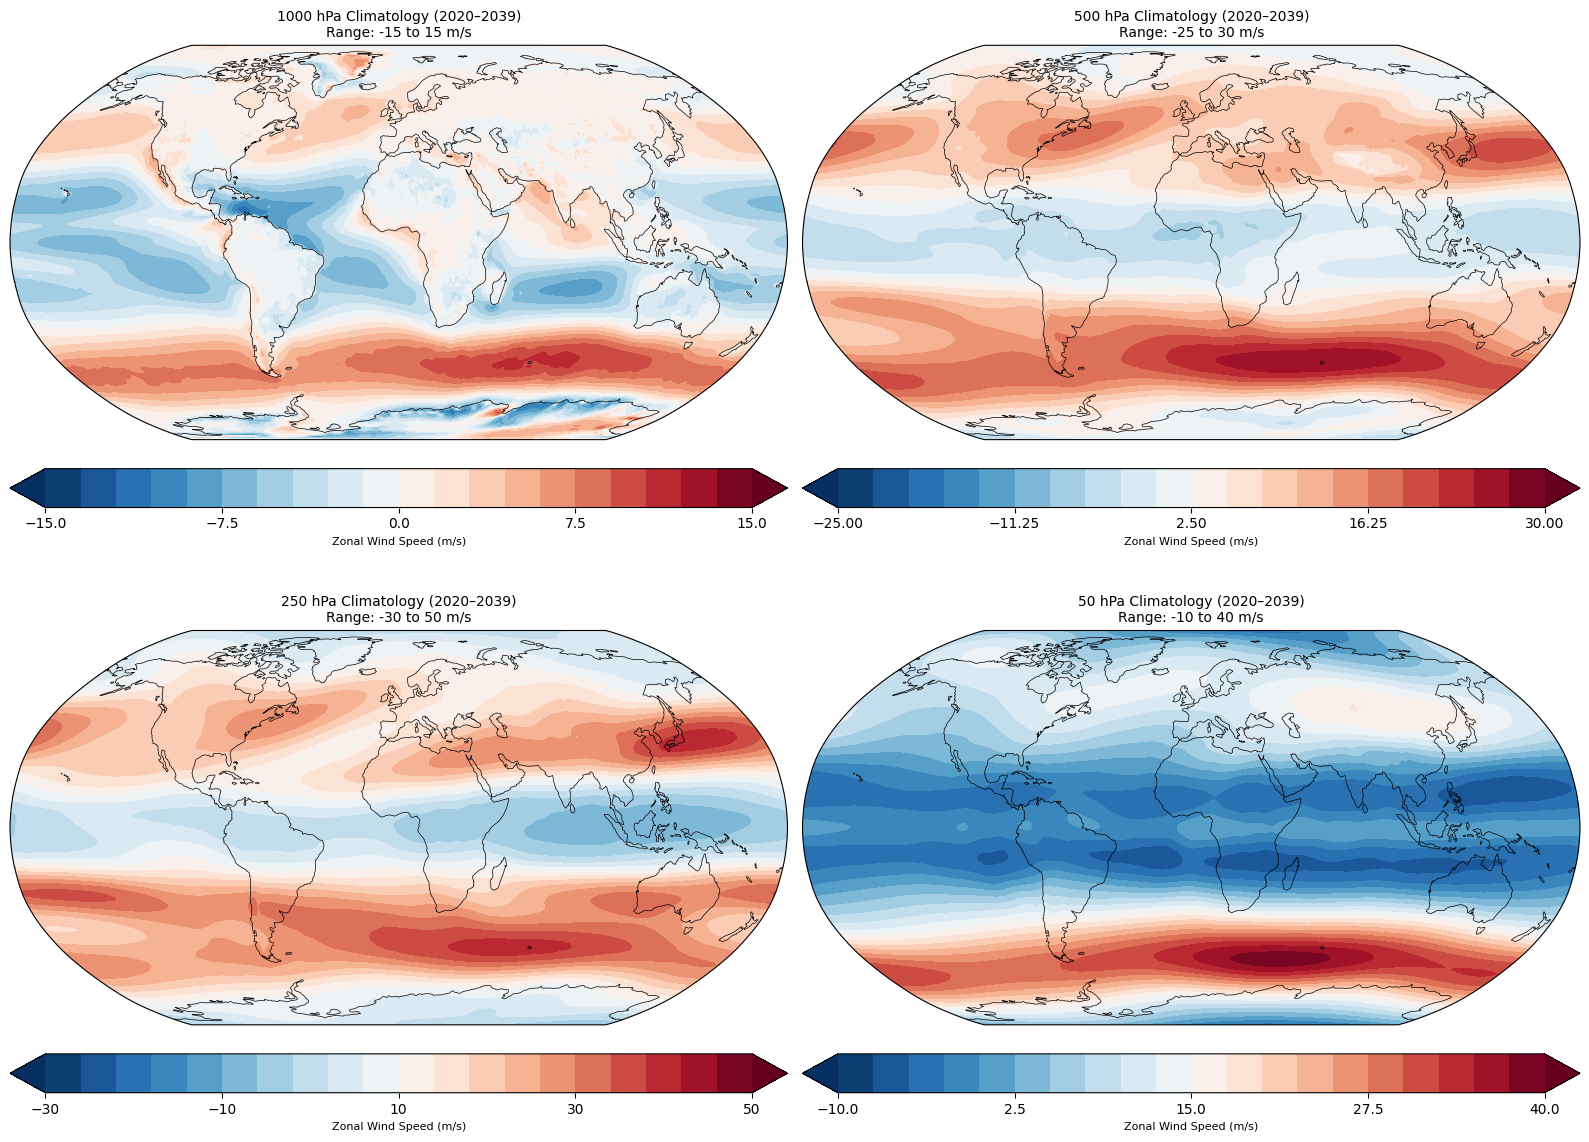

In [5]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Define level-specific wind ranges (m/s)
level_ranges = {
    1000: (-15, 15),   # Surface: easterlies/westerlies
    500: (-25, 30),    # Mid-troposphere (stronger jets)
    250: (-30, 50),    # Upper-troposphere (jet streams)
    50: (-10, 40)      # Stratosphere (weaker winds)
}

# Create a 2x2 plot layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12),
                         subplot_kw={'projection': ccrs.Robinson()})
axes = axes.flatten()

# Loop through each level and plot
for ax, level in zip(axes, levels):
    data = grid_u[level]
    vmin, vmax = level_ranges[level]
    
    # Plot interpolated field
    cf = ax.contourf(
        lon_grid, lat_grid, data,
        levels=np.linspace(vmin, vmax, 21),
        cmap='RdBu_r',
        transform=ccrs.PlateCarree(),
        extend='both'
    )

    # Add coastlines and title
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.set_title(f"{level} hPa Climatology (2020â€“2039)\nRange: {vmin} to {vmax} m/s", fontsize=10)

    # Add horizontal colorbar
    cbar = fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05)
    cbar.set_label("Zonal Wind Speed (m/s)", fontsize=8)
    cbar.set_ticks(np.linspace(vmin, vmax, 5))

# Final layout adjustment
plt.tight_layout()
plt.show()

### Zonal Mean

In [20]:
# Load Climatology Dataset

import xarray as xr

# Load climatology dataset
ds_u = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_ums/climatology_u_all_levels_2020-2039.nc")

# Quick check of the dimensions and variables
print(ds_u)

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    u              (isobaricInhPa, values) float32 ...


In [21]:
# Compute the Zonal Mean

import numpy as np
import pandas as pd
import xarray as xr

# Add latitude as a coordinate (to enable groupby)
ds_u.coords['lat'] = ('values', ds_u.latitude.values)

# Group by latitude and compute mean over longitude (zonal mean)
# Since each "values" index is a full lat-lon point, group by lat directly
zonal_mean = ds_u.u.groupby('lat').mean(dim='values')  # dims: (isobaricInhPa, lat)

# Check shape and sample
print(zonal_mean.shape)
print(zonal_mean)

(25, 511)
<xarray.DataArray 'u' (isobaricInhPa: 25, lat: 511)>
array([[ 9.9393845e-02, -2.3647690e-01, -5.6934506e-01, ...,
        -3.6356162e-02, -2.4355665e-02, -1.1237077e-02],
       [ 9.9393606e-02, -2.3647690e-01, -5.6934518e-01, ...,
        -1.3813485e-02, -8.8673830e-03, -7.0512891e-03],
       [ 9.9393606e-02, -2.3647690e-01, -5.6934506e-01, ...,
         2.0799239e-03,  9.3530118e-04, -5.6049079e-03],
       ...,
       [ 4.7409552e-01,  9.4336081e-01,  1.4090528e+00, ...,
         8.0356956e-01,  5.3339481e-01,  2.6518220e-01],
       [ 5.4996473e-01,  1.0935266e+00,  1.6358643e+00, ...,
         8.6931020e-01,  5.8048785e-01,  2.9178840e-01],
       [ 7.0432734e-01,  1.3995874e+00,  2.0930300e+00, ...,
         8.8431734e-01,  5.9325695e-01,  2.9818332e-01]], dtype=float32)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
  * lat            (lat) float64 -89.63 -89.27 -88.9 -88.54 ... 88.9 89

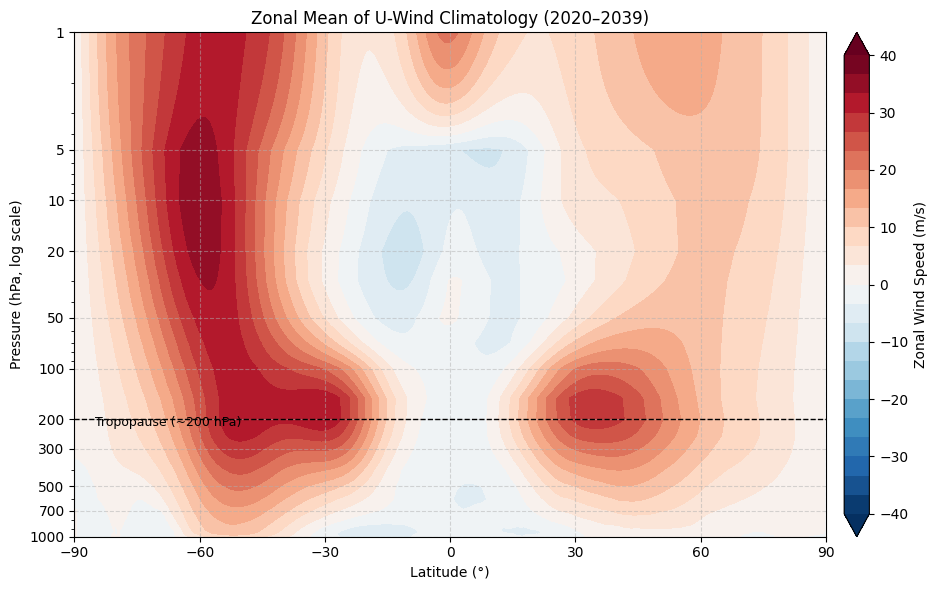

In [22]:
# Plot the Zonal Mean (Pressure vs Latitude Cross-Section)

import matplotlib.pyplot as plt

# Set up figure
fig, ax = plt.subplots(figsize=(10, 6))

# Prepare data
lat = zonal_mean.lat
pressure = zonal_mean.isobaricInhPa
data = zonal_mean.values  # Already in m/s

# Create contour plot
cf = ax.contourf(
    lat, pressure, data,
    levels=np.linspace(-40, 40, 25),
    cmap='RdBu_r', extend='both'
)

# Invert y-axis (pressure decreases with height)
ax.invert_yaxis()
ax.set_yscale('log')

# Custom pressure ticks
ax.set_yticks([1000, 700, 500, 300, 200, 100, 50, 20, 10, 5, 1])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_ylabel("Pressure (hPa, log scale)", fontsize=10)

# Latitude ticks
ax.set_xticks(np.arange(-90, 91, 30))
ax.set_xlabel("Latitude (Â°)", fontsize=10)

# Tropopause line (~200 hPa)
ax.axhline(y=200, color='k', linestyle='--', linewidth=1)
ax.text(-85, 220, "Tropopause (~200 hPa)", fontsize=9, color='k')

# Title and colorbar
ax.set_title("Zonal Mean of U-Wind Climatology (2020â€“2039)", fontsize=12)
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label("Zonal Wind Speed (m/s)", fontsize=10)

# Grid
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 5 yrs differences

In [1]:
import xarray as xr
import numpy as np
import os

# Directory with annual means
annual_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_ums/"
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_ums/"

os.makedirs(output_dir, exist_ok=True)

# ---- Load and average for first 5 years ----
first_years = [2020, 2021, 2022, 2023, 2024]
first_5yr_ds = xr.concat(
    [xr.open_dataset(os.path.join(annual_dir, f"annual_mean_u_all_levels_{year}.nc")) for year in first_years],
    dim="year"
)
first_5yr_mean = first_5yr_ds.mean(dim="year")

# ---- Load and average for last 5 years ----
last_years = [2035, 2036, 2037, 2038, 2039]
last_5yr_ds = xr.concat(
    [xr.open_dataset(os.path.join(annual_dir, f"annual_mean_u_all_levels_{year}.nc")) for year in last_years],
    dim="year"
)
last_5yr_mean = last_5yr_ds.mean(dim="year")

# ---- Compute difference ----
u_diff = last_5yr_mean.u - first_5yr_mean.u
u_diff = u_diff.assign_attrs(units="m/s", long_name="Î”U (2035â€“2039 minus 2020â€“2024)")

# ---- Save all three files ----
first_5yr_mean.to_netcdf(os.path.join(output_dir, "first_5yr_mean_u_2020_2024.nc"))
last_5yr_mean.to_netcdf(os.path.join(output_dir, "last_5yr_mean_u_2035_2039.nc"))
u_diff.to_dataset(name="delta_u").to_netcdf(
    os.path.join(output_dir, "u_diff_2035_2039_minus_2020_2024.nc")
)

print("âœ… Saved:")
print(" - first_5yr_mean_u_2020_2024.nc")
print(" - last_5yr_mean_u_2035_2039.nc")
print(" - u_diff_2035_2039_minus_2020_2024.nc")

âœ… Saved:
 - first_5yr_mean_u_2020_2024.nc
 - last_5yr_mean_u_2035_2039.nc
 - u_diff_2035_2039_minus_2020_2024.nc


In [10]:
### Just check

import xarray as xr

# Load the difference dataset
fiveyrsFirst = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_ums/first_5yr_mean_u_2020_2024.nc")

# Check basic structure
print(fiveyrsFirst)



<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    u              (isobaricInhPa, values) float32 ...


In [2]:
import xarray as xr

# Load the difference dataset
diff_ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_ums/u_diff_2035_2039_minus_2020_2024.nc")

# Check basic structure
print(diff_ds)

# Get the shape of delta_u: (pressure_levels, pixels)
print("Shape of delta_u:", diff_ds.delta_u.shape)

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    delta_u        (isobaricInhPa, values) float32 ...
Shape of delta_u: (25, 196608)


In [3]:
import numpy as np

# Extract latitude values
lat_values = diff_ds.latitude.values

# Print some basic checks
print("Latitude shape:", lat_values.shape)
print("Sample latitudes (first 10):", np.round(lat_values[:10], 4))

# Check the number of unique latitude values
unique_latitudes = np.unique(lat_values)
print("Number of unique latitudes:", len(unique_latitudes))

Latitude shape: (196608,)
Sample latitudes (first 10): [0.2984 0.5968 0.5968 0.8953 0.8953 1.1937 1.1937 1.4922 0.8953 1.1937]
Number of unique latitudes: 511


In [4]:
import pandas as pd
import xarray as xr

# Add 'lat' coordinate to enable groupby
diff_ds.coords['lat'] = ('values', diff_ds.latitude.values)

# Group by latitude and compute mean over all pixels at same latitude
zonal_mean_delta_u = diff_ds.delta_u.groupby('lat').mean(dim='values')

# Confirm shape: should be (25, 511) [pressure levels x latitude]
print("Zonal mean shape (pressure x latitude):", zonal_mean_delta_u.shape)

# Print sample
print(zonal_mean_delta_u)

Zonal mean shape (pressure x latitude): (25, 511)
<xarray.DataArray 'delta_u' (isobaricInhPa: 25, lat: 511)>
array([[-0.01962127, -0.00533102, -0.01357282, ...,  0.02067542,
         0.01411256,  0.01633841],
       [-0.01962135, -0.00533105, -0.01357273, ...,  0.00704289,
         0.00072038,  0.0068028 ],
       [-0.01962123, -0.00533106, -0.01357273, ...,  0.02595794,
         0.01131211,  0.01378171],
       ...,
       [-0.03169671, -0.05933456, -0.09350955, ..., -0.03159472,
        -0.01935828, -0.01031539],
       [-0.01653257, -0.04631776, -0.06442764, ..., -0.05612836,
        -0.03112328, -0.01529771],
       [ 0.00042981,  0.01686355,  0.03245242, ..., -0.20898493,
        -0.13575482, -0.05623448]], dtype=float32)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
  * lat            (lat) float64 -89.63 -89.27 -88.9 -88.54 ... 88.9 89.27 89.63
Attributes:
    units:      m/s
    long_name:  Î”U 

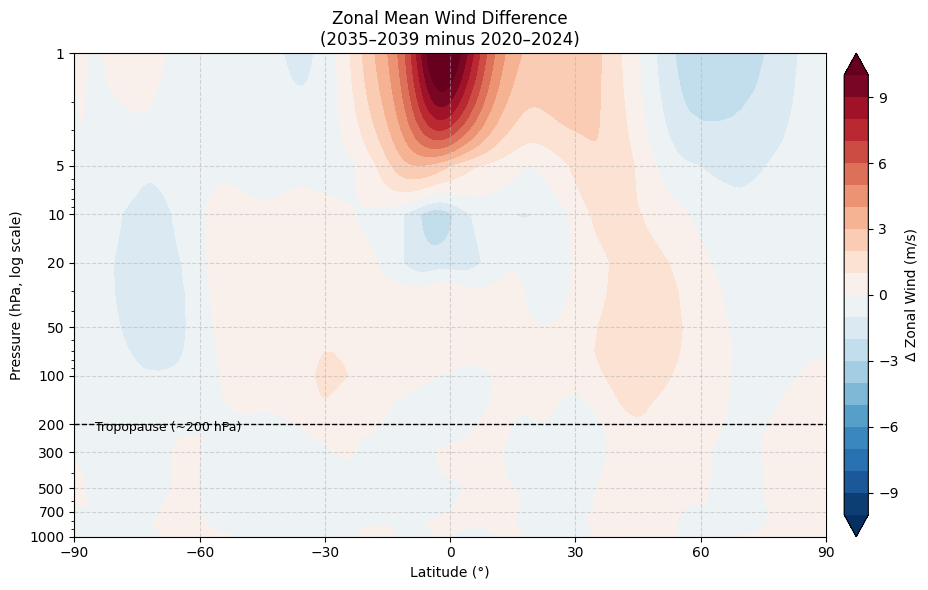

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Extract axes
latitudes = zonal_mean_delta_u.lat
pressures = zonal_mean_delta_u.isobaricInhPa
delta_u = zonal_mean_delta_u.values  # in m/s

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))

# Adjust contour levels for wind (typical range might be Â±5 m/s)
cf = ax.contourf(
    latitudes, pressures, delta_u,
    levels=np.linspace(-10, 10, 21),  # Adjust range as needed
    cmap='RdBu_r',  # Blue-red colormap (reversed for conventional wind plotting)
    extend='both'
)

# Invert pressure axis (top = high altitude)
ax.invert_yaxis()
ax.set_yscale('log')

# Customize ticks and labels
ax.set_yticks([1000, 700, 500, 300, 200, 100, 50, 20, 10, 5, 1])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_ylabel("Pressure (hPa, log scale)", fontsize=10)
ax.set_xlabel("Latitude (Â°)", fontsize=10)
ax.set_xticks(np.arange(-90, 91, 30))

# Add tropopause line
ax.axhline(y=200, color='k', linestyle='--', linewidth=1)
ax.text(-85, 220, "Tropopause (~200 hPa)", fontsize=9, color='k')

# Colorbar
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label("Î” Zonal Wind (m/s)", fontsize=10)

# Title and grid
ax.set_title("Zonal Mean Wind Difference\n(2035â€“2039 minus 2020â€“2024)", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

=== Equatorial Zonal Wind (1-5 hPa) ===

First period shape: (2, 3584)
Last period shape: (2, 3584)

Pressure (hPa) | 2020-2024 (m/s) | 2035-2039 (m/s) | Difference
--------------------------------------------------------
         1.0 |           12.69 |           24.00 |      11.30
         5.0 |           -9.63 |           -7.69 |       1.95


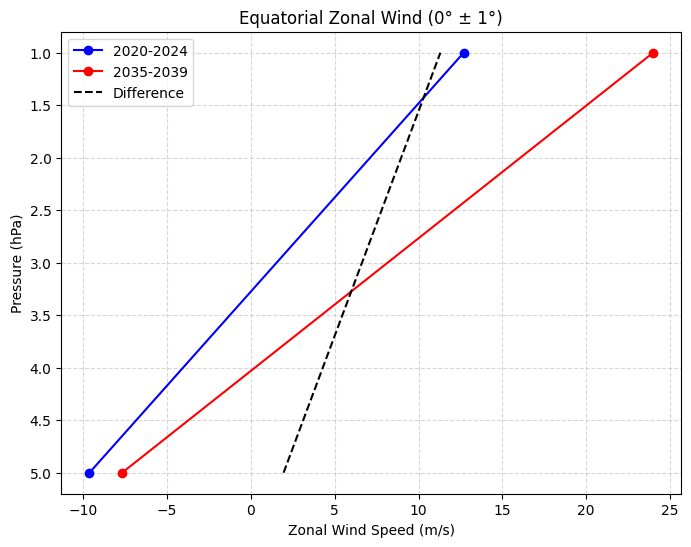

In [12]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Load datasets with proper decoding
first_5yr = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_ums/first_5yr_mean_u_2020_2024.nc")
last_5yr = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_ums/last_5yr_mean_u_2035_2039.nc")

# Create proper latitude coordinate (assuming it's stored in the 'latitude' variable)
first_5yr.coords['lat'] = ('values', first_5yr.latitude.values)
last_5yr.coords['lat'] = ('values', last_5yr.latitude.values)

# Select equatorial region (0Â° Â± 1Â°) and pressure range (1-5 hPa)
equator_mask = (np.abs(first_5yr.lat) <= 1.0)
pressure_mask = (first_5yr.isobaricInhPa >= 1) & (first_5yr.isobaricInhPa <= 5)

# Extract values
first_equator = first_5yr.u.where(equator_mask & pressure_mask, drop=True)
last_equator = last_5yr.u.where(equator_mask & pressure_mask, drop=True)

# Print comparison
print("=== Equatorial Zonal Wind (1-5 hPa) ===")
print(f"\nFirst period shape: {first_equator.shape}")
print(f"Last period shape: {last_equator.shape}")

# Calculate mean profiles
first_profile = first_equator.mean(dim='values')
last_profile = last_equator.mean(dim='values')

# Print values at each pressure level
print("\nPressure (hPa) | 2020-2024 (m/s) | 2035-2039 (m/s) | Difference")
print("--------------------------------------------------------")
for p in sorted(first_profile.isobaricInhPa.values):
    first_val = first_profile.sel(isobaricInhPa=p).item()
    last_val = last_profile.sel(isobaricInhPa=p).item()
    print(f"{p:>12.1f} | {first_val:>15.2f} | {last_val:>15.2f} | {last_val-first_val:>10.2f}")

# Plot vertical profiles
plt.figure(figsize=(8, 6))
plt.plot(first_profile, first_profile.isobaricInhPa, 'b-o', label='2020-2024')
plt.plot(last_profile, last_profile.isobaricInhPa, 'r-o', label='2035-2039')
plt.plot(last_profile - first_profile, last_profile.isobaricInhPa, 'k--', label='Difference')

plt.gca().invert_yaxis()
plt.title("Equatorial Zonal Wind (0Â° Â± 1Â°)")
plt.xlabel("Zonal Wind Speed (m/s)")
plt.ylabel("Pressure (hPa)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Trend

In [13]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import os

# Configuration
annual_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_ums/"
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_ums/"
os.makedirs(output_dir, exist_ok=True)

# Load all annual files
years = range(2020, 2040)
ds_list = []
print(ds_list)

for year in years:
    file = os.path.join(annual_dir, f"annual_mean_u_all_levels_{year}.nc")
    ds = xr.open_dataset(file)
    ds['year'] = year  # Add year coordinate
    ds_list.append(ds)

# Combine into single dataset
full_ds = xr.concat(ds_list, dim='year')

# Add proper latitude coordinate if needed
if 'lat' not in full_ds.coords:
    full_ds.coords['lat'] = ('values', full_ds.latitude.values)

[]


In [14]:
### Trend Calculation

# Calculate linear trends at each pressure level and latitude
def calculate_trend(y, x):
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    return slope  # Trend per decade

# Convert to pandas DataFrame for efficient computation
df = full_ds.u.to_dataframe().reset_index()

# Group by pressure level and latitude (or 'values' if needed)
grouped = df.groupby(['isobaricInhPa', 'lat'])

# Calculate trends
trends = grouped.apply(
    lambda g: calculate_trend(g['u'], g['year'])
).to_xarray().rename('u_trend')

# Convert back to clean xarray Dataset
trends_ds = trends.to_dataset()
trends_ds.attrs['units'] = 'm/s/year'
trends_ds.attrs['description'] = 'Zonal wind linear trends (2020-2039)'

# Save the trends
trends_ds.to_netcdf(os.path.join(output_dir, 'zonal_wind_trends_2020-2039.nc'))

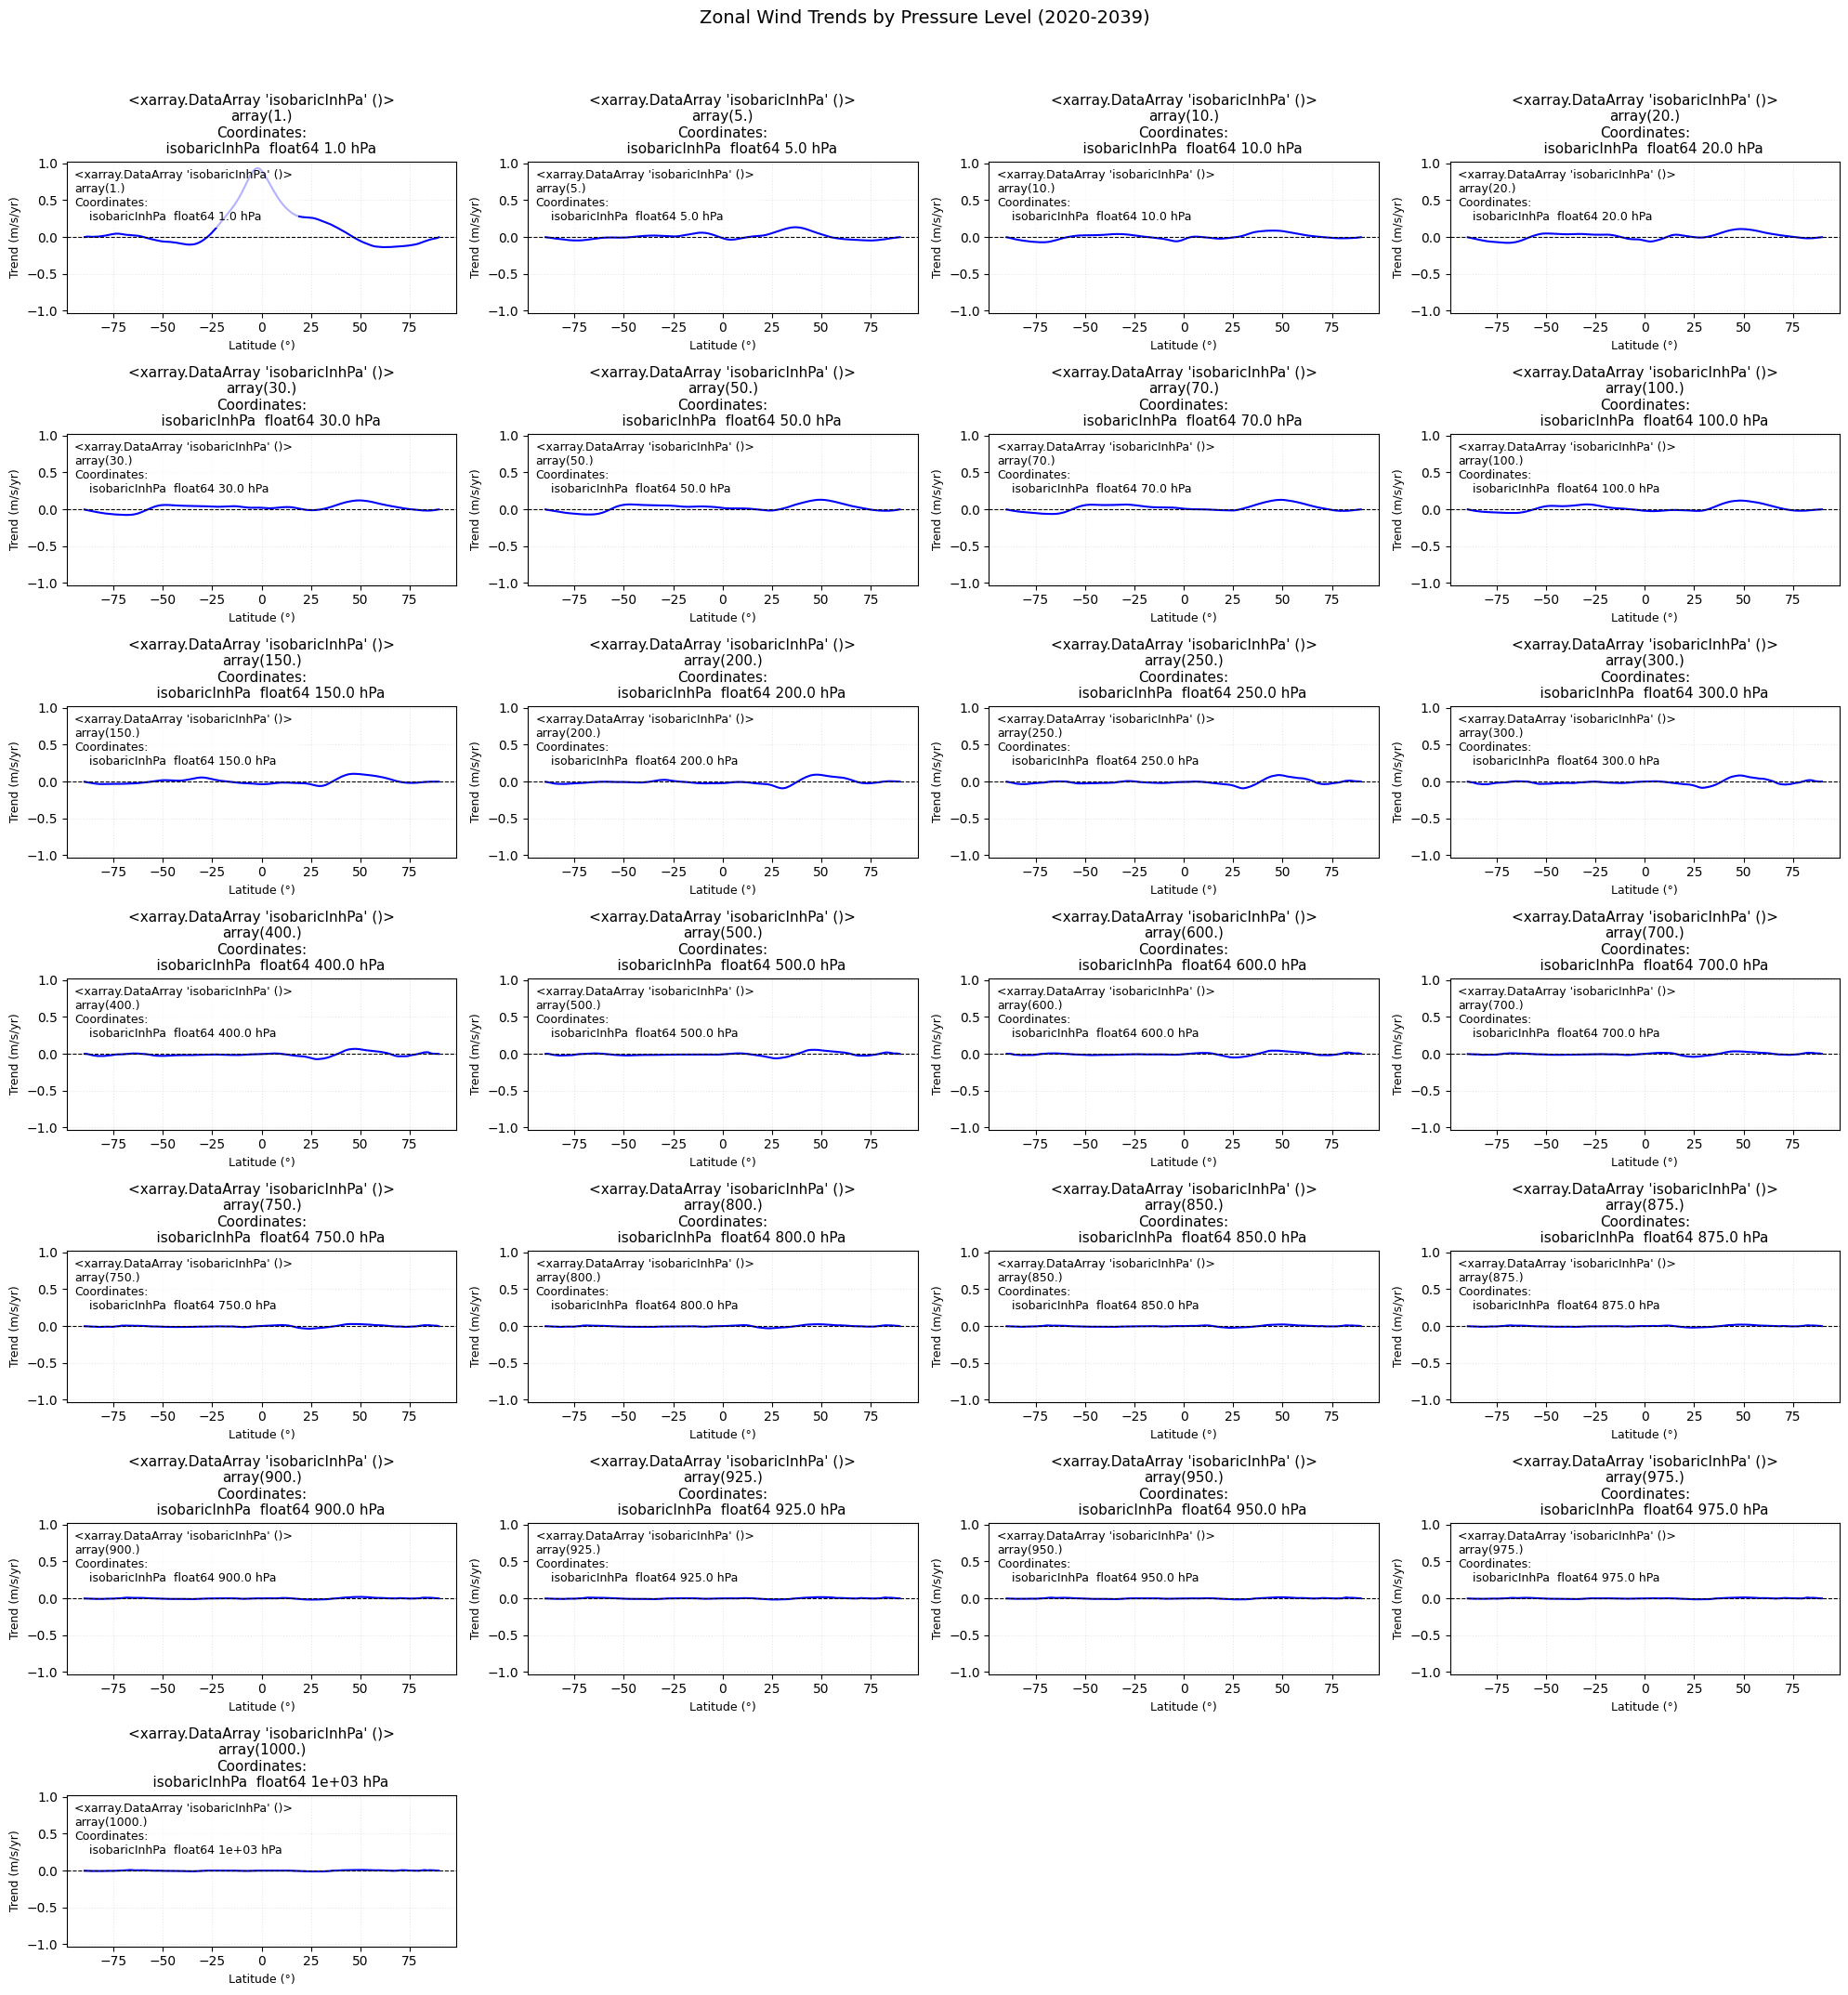

In [15]:
# Create subplot grid for pressure level trends
pressure_levels = trends_ds.isobaricInhPa
n_levels = len(pressure_levels)

# Calculate grid dimensions
ncols = 4  # Adjust number of columns as needed
nrows = int(np.ceil(n_levels / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 3*nrows))
axes = axes.flatten()  # Flatten for easy iteration

# Find global max trend for consistent y-axis scaling
global_max = np.max(np.abs(trends_ds.u_trend.values))

for i, (ax, p) in enumerate(zip(axes, pressure_levels)):
    p_trend = trends_ds.u_trend.sel(isobaricInhPa=p)
    
    # Main plot
    ax.plot(p_trend.lat, p_trend, 'b-', linewidth=1.5)
    ax.axhline(0, color='k', linestyle='--', linewidth=0.8)
    
    # Formatting
    ax.set_title(f'{p} hPa', fontsize=11)
    ax.set_xlabel('Latitude (Â°)', fontsize=9)
    ax.set_ylabel('Trend (m/s/yr)', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.3)
    
    # Consistent y-axis limits
    ax.set_ylim(-global_max*1.1, global_max*1.1)
    
    # Add pressure label in corner
    ax.text(0.02, 0.95, f'{p} hPa', transform=ax.transAxes, 
            fontsize=9, va='top', ha='left', 
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

# Hide empty subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Common title
plt.suptitle('Zonal Wind Trends by Pressure Level (2020-2039)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

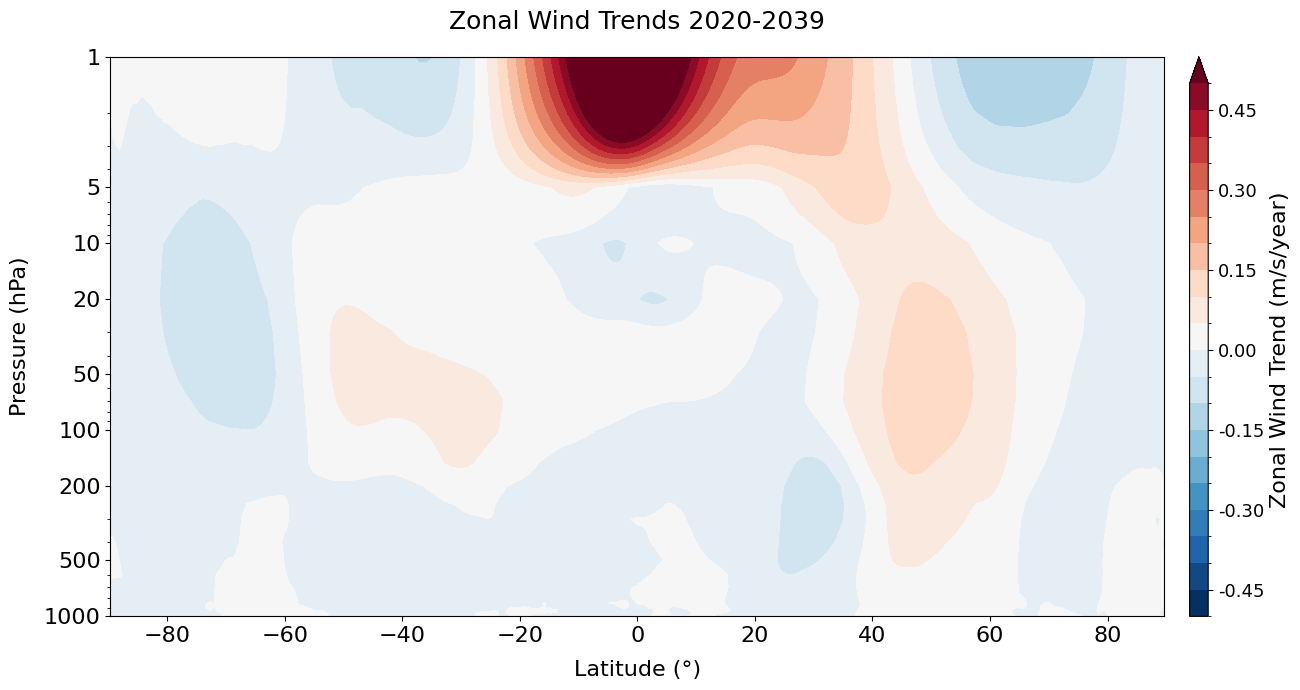

In [18]:
# 2D contour plot of zonal wind trends
import matplotlib.ticker

plt.figure(figsize=(14, 7))

# Create contour levels symmetric around zero
max_trend = np.max(np.abs(trends_ds.u_trend.values))
levels = np.linspace(-0.5, 0.5, 21)

# Plot
contour = trends_ds.u_trend.plot.contourf(
    x='lat',
    y='isobaricInhPa',
    levels=levels,
    cmap='RdBu_r',
    add_colorbar=True,
    cbar_kwargs={
        'label': 'Zonal Wind Trend (m/s/year)',
        'orientation': 'vertical',
        'pad': 0.02,
        'aspect': 30
    }
)

# Formatting
plt.yscale('log')
plt.gca().invert_yaxis()
plt.title('Zonal Wind Trends 2020-2039', pad=20, fontsize=18)
plt.xlabel('Latitude (Â°)', labelpad=10, fontsize=16)
plt.ylabel('Pressure (hPa)', labelpad=10, fontsize=16)

# Improve tick labels
plt.yticks([1000, 500, 200, 100, 50, 20, 10, 5, 1], 
           ['1000', '500', '200', '100', '50', '20', '10', '5', '1'],
           fontsize=16)
plt.xticks(fontsize=16)

# Colorbar adjustments
cbar = contour.colorbar
cbar.set_label('Zonal Wind Trend (m/s/year)', fontsize=16)
cbar.formatter = matplotlib.ticker.FormatStrFormatter('%.2f')  # 2 decimal places
cbar.ax.tick_params(labelsize=13)

#plt.grid(True, linestyle='--', alpha=0.3, which='both')
plt.tight_layout()
plt.show()

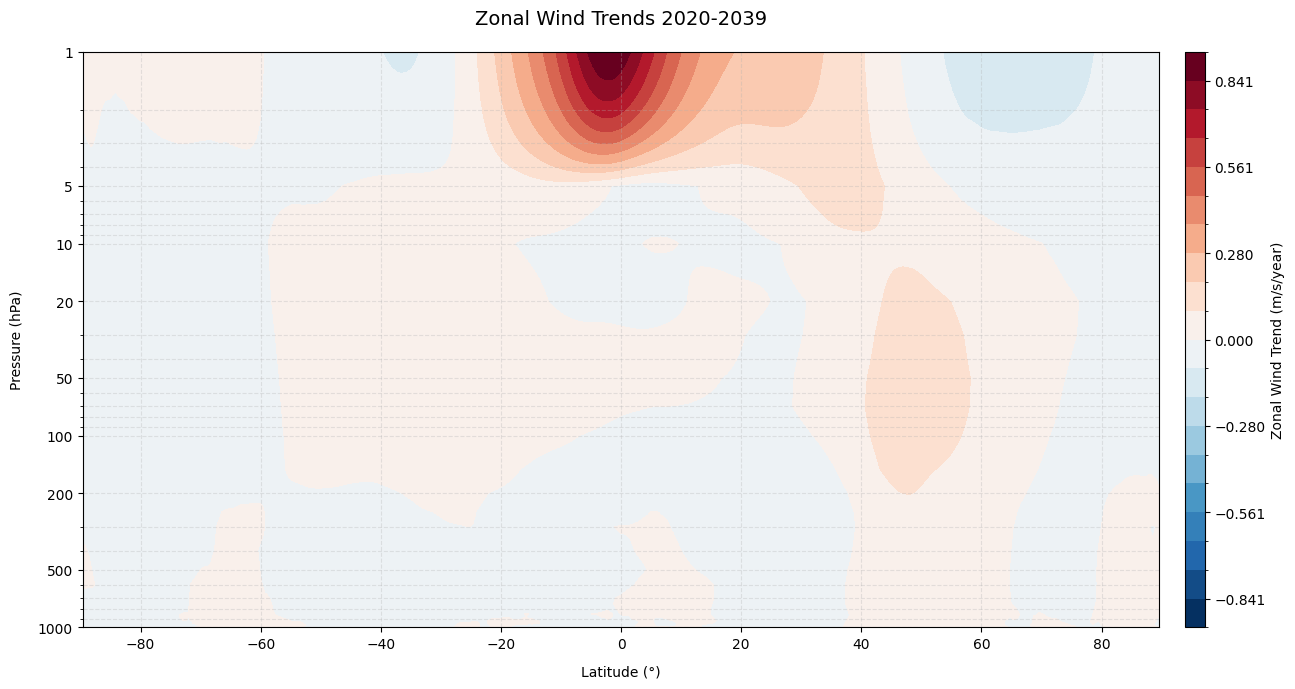

In [8]:
# 2D contour plot of all trends
plt.figure(figsize=(14, 7))

# Create contour levels symmetric around zero
max_trend = np.max(np.abs(trends_ds.u_trend.values))
levels = np.linspace(-max_trend, max_trend, 21)

# Plot
contour = trends_ds.u_trend.plot.contourf(
    x='lat',
    y='isobaricInhPa',
    levels=levels,
    cmap='RdBu_r',
    add_colorbar=True,
    cbar_kwargs={
        'label': 'Zonal Wind Trend (m/s/year)',
        'orientation': 'vertical',
        'pad': 0.02,
        'aspect': 30
    }
)

# Formatting
plt.yscale('log')
plt.gca().invert_yaxis()
plt.title('Zonal Wind Trends 2020-2039', pad=20, fontsize=14)
plt.xlabel('Latitude (Â°)', labelpad=10)
plt.ylabel('Pressure (hPa)', labelpad=10)

# Improve tick labels
plt.yticks([1000, 500, 200, 100, 50, 20, 10, 5, 1], 
           ['1000', '500', '200', '100', '50', '20', '10', '5', '1'])
plt.grid(True, linestyle='--', alpha=0.3, which='both')

plt.tight_layout()
plt.show()

## Temperature

### Check Data

In [3]:
# @ Levante
pathpl_dy_t = f"{PROJ2559_DIR}/pl_dy/tco2559_proj/0001_pl_t_healpix_hourly_2034.grb"
data_pl_dy_t = xr.open_dataset(pathpl_dy_t, engine="cfgrib")
data_pl_dy_t

<xarray.Dataset>
Dimensions:        (time: 365, isobaricInhPa: 25, values: 196608)
Coordinates:
  * time           (time) datetime64[ns] 2034-01-01 2034-01-02 ... 2034-12-31
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
    valid_time     (time) datetime64[ns] ...
Dimensions without coordinates: values
Data variables:
    t              (time, isobaricInhPa, values) float32 ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          1003
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-04-14T22:43 GRIB to CDM+CF via cfgrib-0.9.1...

/tmp/ipykernel_486172/3004361477.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


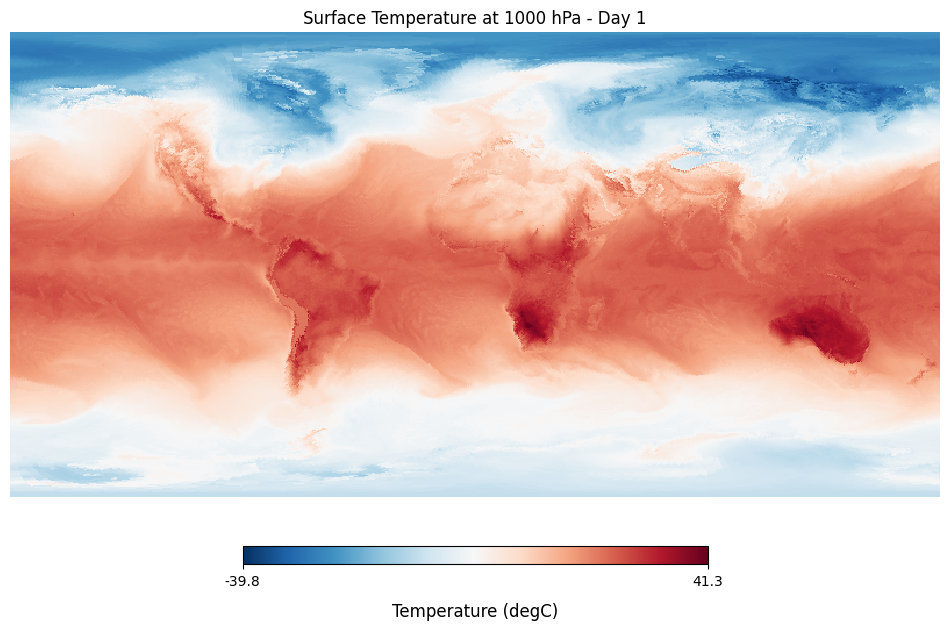

In [5]:
# Select surface level (1000 hPa) and first timestep
t_surface = data_pl_dy_t.t.isel(time=0, isobaricInhPa=0)  # Index 0 = 1000 hPa

# Convert to numpy array
t_surface_map = t_surface.values - 275.15

# Plot settings
plt.figure(figsize=(12, 8))

# Plot the map using Healpy's cartview (just the variable, no overlays)
hp.cartview(
    t_surface_map,
    flip="geo",          # Match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING)
    lonra=[-180, 180],   # Full longitude range
    latra=[-90, 90],     # Full latitude range
    title="Surface Temperature at 1000 hPa - Day 1",
    min=None,            # Auto color scale
    max=None,
    cmap="RdBu_r",       # Red-Blue for winds (negative=easterly, positive=westerly)
    badcolor="gray",     # Missing data color
    hold=True,
)

# Customize colorbar only
cbar = plt.gcf().axes[-1]
cbar.set_xlabel("Temperature (degC)", fontsize=12, labelpad=10)

# Adjust layout
plt.tight_layout()
plt.show()

### Monthly means: Compute and save

In [2]:
import os
import xarray as xr

# Define paths (adjust to your temperature data)
base_path = f"{PROJ2559_DIR}/pl_dy/tco2559_proj/0001_pl_t_healpix_hourly_"  # Temperature files
years = range(2020, 2040)
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_tem/"  # New directory for temperature

#os.makedirs(output_dir, exist_ok=True)

In [8]:
# for year in years:
#     file_path = f"{base_path}{year}.grb"
#     print(f"Processing {year}...")
    
#     with xr.open_dataset(file_path, engine="cfgrib", chunks={"time": 1000}) as ds:
#         # Extract temperature variable (typically 't' in GRIB)
#         temp = ds['t']  # Change to correct variable name if needed
        
#         # Monthly means (preserves all 25 levels)
#         monthly_means = temp.groupby("time.month").mean(dim="time").compute()
        
#         # Save
#         output_file = f"{output_dir}monthly_mean_t_all_levels_{year}.nc"
#         monthly_means.to_dataset(name="t").to_netcdf(output_file)

Processing 2020...
Processing 2021...
Processing 2022...
Processing 2023...
Processing 2024...
Processing 2025...
Processing 2026...
Processing 2027...
Processing 2028...
Processing 2029...
Processing 2030...
Processing 2031...
Processing 2032...
Processing 2033...
Processing 2034...
Processing 2035...
Processing 2036...
Processing 2037...
Processing 2038...
Processing 2039...


In [3]:
# Check one output file
test = xr.open_dataset(f"{output_dir}monthly_mean_t_all_levels_2030.nc")
print(test)

# Expected output:
# <xarray.Dataset>
# Dimensions:  (month: 12, values: 196608)
# Coordinates:
#   * month    (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
# Data variables:
#     u        (month, values) float32 ...

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608, month: 12)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
  * month          (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
Dimensions without coordinates: values
Data variables:
    t              (month, isobaricInhPa, values) float32 ...


### Annual means: Compute and Save

In [4]:
# Concatenate & Add Time Coordinates

datasets = []
for year in years:
    ds = xr.open_dataset(f"{output_dir}monthly_mean_t_all_levels_{year}.nc")
    time = xr.cftime_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=("month", time))  # Add time coordinate
    datasets.append(ds)

# Concatenate all years
ds_T = xr.concat(datasets, dim="month")

In [5]:
# Compute Annual Means and Save

annual_means_T = ds_T.t.groupby("time.year").mean(dim="month")

# Save annual means
for year in annual_means_T.year.values:
    annual_means_T.sel(year=year).to_dataset(name="t").to_netcdf(
        f"{output_dir}annual_mean_t_all_levels_{year}.nc"
    )

In [7]:
# Long-Term Climatology and Save

climatology_T = annual_means_T.mean(dim="year")
climatology_T.to_dataset(name="t").to_netcdf(
    f"{output_dir}climatology_t_all_levels_2020-2039.nc"
)

### Plot: Climatology

In [26]:
import healpy as hp
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Load climatology data
ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_tem/climatology_t_all_levels_2020-2039.nc")

# Select 4 levels: 1000, 500, 250, 50 hPa
levels = [1000, 500, 250, 50]
t_data = {level: ds.t.sel(isobaricInhPa=level, method="nearest").values for level in levels}

# Create HEALPix grid (with correct resolution based on the dataset)
nside = hp.npix2nside(len(ds['t'].values[0]))  # HEALPix resolution
pixel_lats = hp.pix2ang(nside, np.arange(len(ds['t'].values[0])), lonlat=True)[1]  # Get latitude in HEALPix order

# Create regular grid from HEALPix latitudes and longitudes
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), np.linspace(-90, 90, 180))

# Interpolate for all levels
grid_T = {}
for level in levels:
    grid_T[level] = np.zeros_like(grid_lat)
    for i in range(grid_lon.shape[0]):
        for j in range(grid_lon.shape[1]):
            grid_T[level][i,j] = hp.get_interp_val(
                np.nan_to_num(t_data[level], nan=0),
                grid_lon[i,j], grid_lat[i,j],
                lonlat=True, nest=True
            )



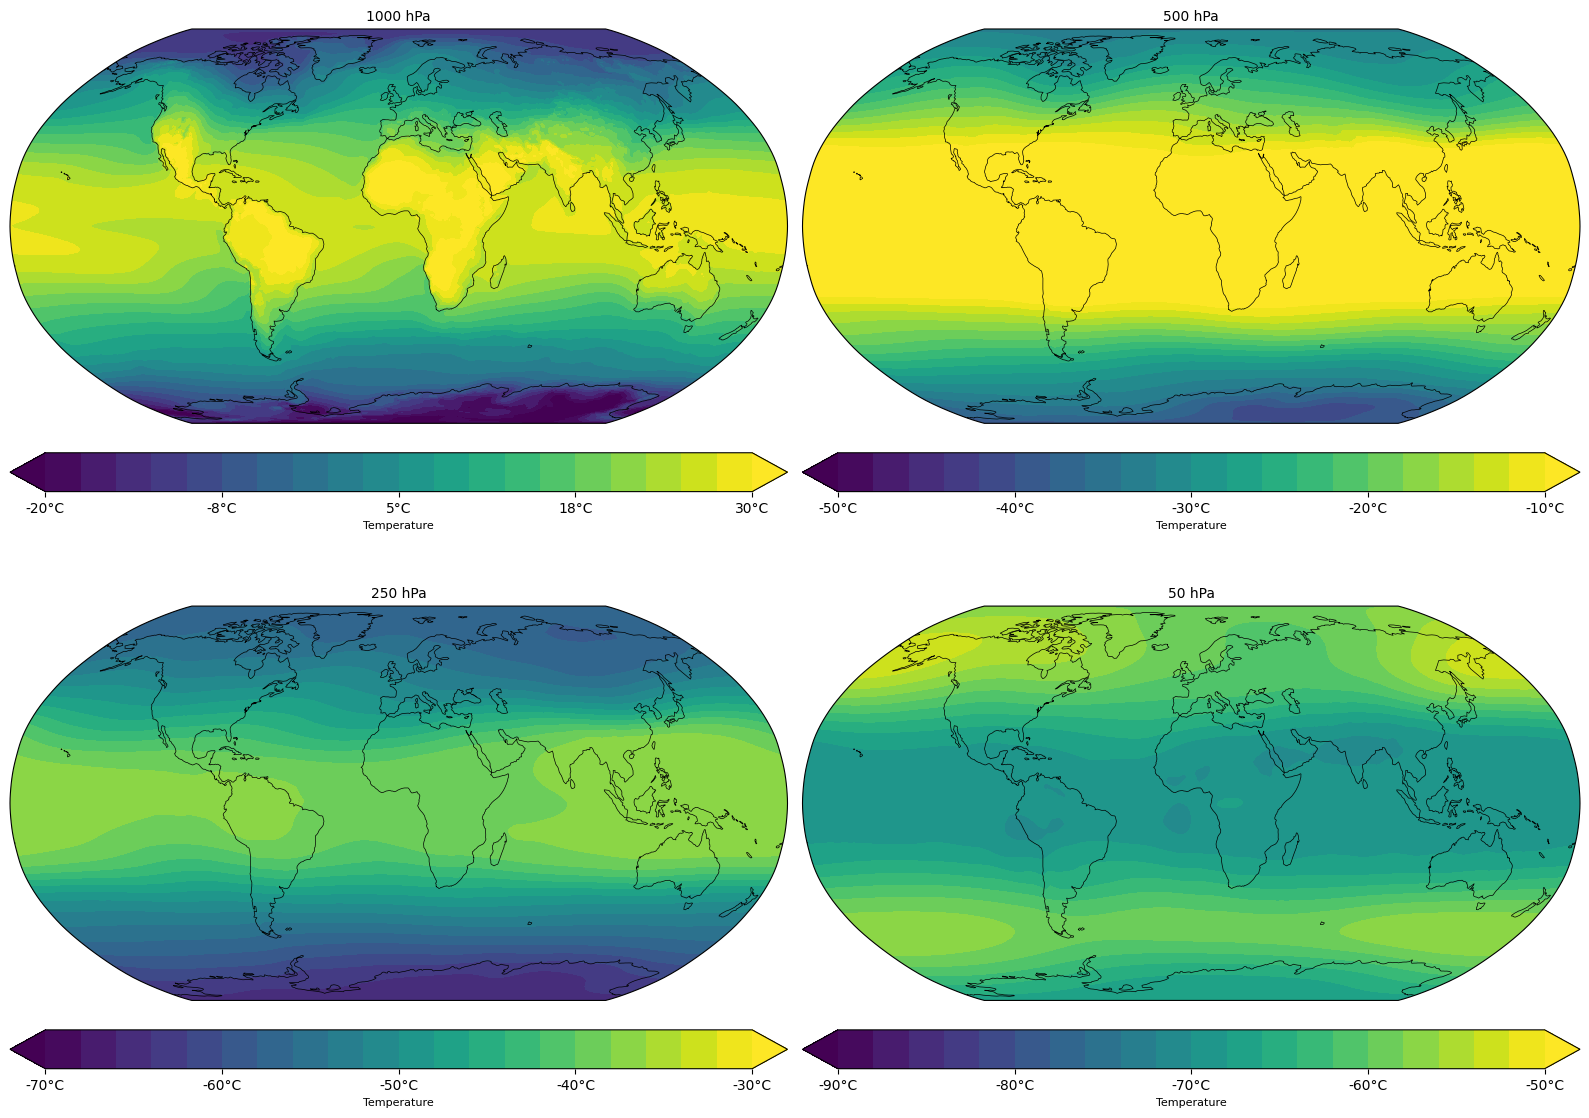

In [27]:
# Plot for each pressure level

fig, axes = plt.subplots(2, 2, figsize=(16, 12), subplot_kw={'projection': ccrs.Robinson()})
axes = axes.flatten()

# Define ranges for the colorbar (in Celsius)
level_ranges_celsius = {
    1000: (-20, 30),
    500: (-50, -10),
    250: (-70, -30),
    50: (-90, -50)
}

level_ranges_kelvin = {level: (tmin+273.15, tmax+273.15) for level, (tmin, tmax) in level_ranges_celsius.items()}

for ax, level in zip(axes, levels):
    data = grid_T[level]
    vmin_k, vmax_k = level_ranges_kelvin[level]

    cf = ax.contourf(grid_lon, grid_lat, data, levels=np.linspace(vmin_k, vmax_k, 21),
                     cmap='viridis', transform=ccrs.PlateCarree(), extend='both')
    
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.set_title(f"{level} hPa", fontsize=10)
    
    cbar = fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05)
    cbar.set_ticks(np.linspace(vmin_k, vmax_k, 5))  # Kelvin ticks
    cbar.set_ticklabels([f"{x-273.15:.0f}Â°C" for x in cbar.get_ticks()])  # Celsius labels
    cbar.set_label("Temperature", fontsize=8)

plt.tight_layout()
plt.show()

### Zonal Mean

In [15]:
# Load Climatology Dataset

import xarray as xr

# Load climatology dataset for temperature
ds_t = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_tem/climatology_t_all_levels_2020-2039.nc")

# Quick check of the dimensions and variables
print(ds_t)

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    t              (isobaricInhPa, values) float32 ...


In [16]:
# Compute Zonal Mean Temperature

import numpy as np
import pandas as pd
import xarray as xr

# Add latitude as a coordinate (to enable groupby)
ds_t.coords['lat'] = ('values', ds_t.latitude.values)

# Group by latitude and compute mean over longitude (zonal mean)
zonal_mean_temp = ds_t.t.groupby('lat').mean(dim='values')  # dims: (isobaricInhPa, lat)

# Check shape and a sample
print(zonal_mean_temp.shape)
print(zonal_mean_temp)

(25, 511)
<xarray.DataArray 't' (isobaricInhPa: 25, lat: 511)>
array([[251.55464, 251.77617, 252.08266, ..., 261.10886, 261.1078 ,
        261.10663],
       [250.34583, 250.56631, 250.87135, ..., 261.15347, 261.14612,
        261.14185],
       [249.11166, 249.33105, 249.63458, ..., 261.28207, 261.2743 ,
        261.27338],
       ...,
       [219.49356, 219.50113, 219.5084 , ..., 222.33118, 222.32645,
        222.32065],
       [233.74628, 233.75098, 233.75806, ..., 233.64769, 233.64688,
        233.64505],
       [257.96057, 257.9605 , 257.97543, ..., 254.56075, 254.55951,
        254.55411]], dtype=float32)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
  * lat            (lat) float64 -89.63 -89.27 -88.9 -88.54 ... 88.9 89.27 89.63


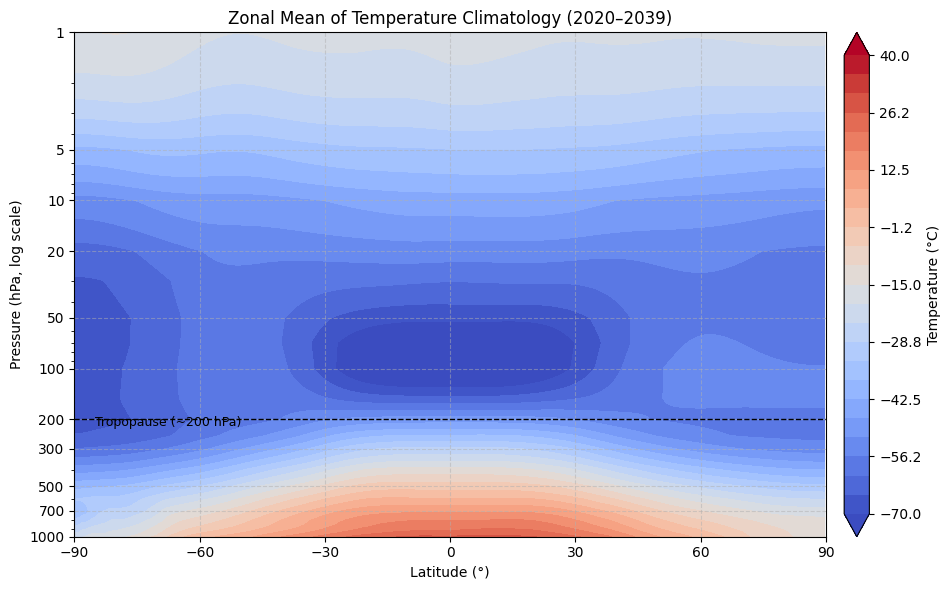

In [19]:
# Plot Zonal Mean Temperature (Â°C)

import matplotlib.pyplot as plt

# Set up figure
fig, ax = plt.subplots(figsize=(10, 6))

# Prepare data
lat = zonal_mean_temp.lat
pressure = zonal_mean_temp.isobaricInhPa
data = zonal_mean_temp.values - 273.15  # Convert K to Â°C

# Create contour plot
cf = ax.contourf(
    lat, pressure, data,
    levels=np.linspace(-70, 40, 25),
    cmap='coolwarm', extend='both'
)

# Invert y-axis (pressure decreases with height)
ax.invert_yaxis()
ax.set_yscale('log')

# Custom pressure levels
ax.set_yticks([1000, 700, 500, 300, 200, 100, 50, 20, 10, 5, 1])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_ylabel("Pressure (hPa, log scale)", fontsize=10)

# Latitude markers
ax.set_xticks(np.arange(-90, 91, 30))
ax.set_xlabel("Latitude (Â°)", fontsize=10)

# Tropopause line (approx. at 200 hPa)
ax.axhline(y=200, color='k', linestyle='--', linewidth=1)
ax.text(-85, 220, "Tropopause (~200 hPa)", fontsize=9, color='k')

# Title and colorbar
ax.set_title("Zonal Mean of Temperature Climatology (2020â€“2039)", fontsize=12)
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label("Temperature (Â°C)", fontsize=10)

# Grid
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

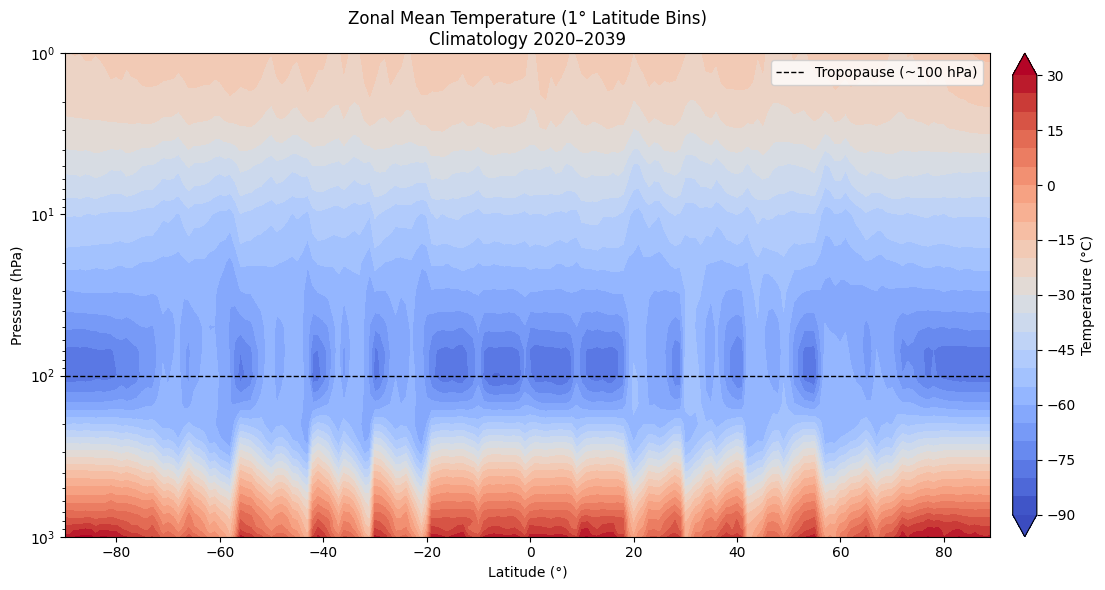

In [24]:
### The Wrong interpolation part: 1Â° Latitude Binning

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp

# Load temperature climatology dataset
ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_tem/climatology_t_all_levels_2020-2039.nc")

# Infer HEALPix nside from number of pixels
nside = hp.npix2nside(len(ds['t'].values[0]))

# Get latitude (in degrees) from HEALPix pixel index
pixel_lats = hp.pix2ang(nside, np.arange(len(ds['t'].values[0])), lonlat=True)[1]

# Add latitude coordinate to dataset
ds.coords['lat'] = ('values', pixel_lats)

# Create 1Â° latitude bins from -90 to 90
lat_bins = np.linspace(-90, 90, 181)

# Group by latitude bins and compute zonal mean
zonal_mean_binned = (
    ds.t.groupby_bins('lat', lat_bins, labels=lat_bins[:-1])
    .mean(dim='values')
    .rename({'lat_bins': 'latitude'})
)

# Convert from Kelvin to Celsius
zonal_mean_binned_celsius = zonal_mean_binned - 273.15

# --- Plotting the binned zonal mean ---
fig, ax = plt.subplots(figsize=(12, 6))

pressure = zonal_mean_binned_celsius.isobaricInhPa.values
latitudes = zonal_mean_binned_celsius.latitude.values
T_data_binned = zonal_mean_binned_celsius.values  # Shape: (25 pressure, 180 latitude)

cf = ax.contourf(
    latitudes,
    pressure,
    T_data_binned,
    levels=np.linspace(-90, 30, 25),
    cmap='coolwarm',
    extend='both'
)

# Formatting
ax.set_yscale('log')
ax.invert_yaxis()
ax.set_xlabel('Latitude (Â°)')
ax.set_ylabel('Pressure (hPa)')
ax.set_title('Zonal Mean Temperature (1Â° Latitude Bins)\nClimatology 2020â€“2039')

# Add colorbar and tropopause line
cbar = plt.colorbar(cf, ax=ax, pad=0.02)
cbar.set_label('Temperature (Â°C)')
ax.axhline(100, color='black', linestyle='--', linewidth=1, label='Tropopause (~100 hPa)')
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ðŸ” Zonal Mean Temperature Comparison: Native vs. 1Â° Binned Latitude

# âœ… Native Resolution
# 	â€¢	The original data had 511 distinct latitude points, which means the latitudes were not evenly spaced. This can happen due to interpolation on a model grid or specific observational platforms.
# 	â€¢	We computed the zonal mean temperature by averaging over all longitudes (here assumed to be included in the values dimension) grouped by each exact latitude.

# âœ… 1Â° Latitude Binning
# 	â€¢	We grouped the data into 1-degree latitude bins (from -90Â° to 90Â°).
# 	â€¢	Each bin aggregates all points falling within its 1-degree range. This method smoothens the high-resolution native data and gives a more standard zonal view often used in climatology.

### 5 yrs differences 

In [2]:
import xarray as xr
import numpy as np
import os

# Directory with annual means
annual_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_tem/"
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_tem/"

os.makedirs(output_dir, exist_ok=True)

# ---- Load and average for first 5 years ----
first_years = [2020, 2021, 2022, 2023, 2024]
first_5yr_ds = xr.concat(
    [xr.open_dataset(os.path.join(annual_dir, f"annual_mean_t_all_levels_{year}.nc")) for year in first_years],
    dim="year"
)
first_5yr_mean = first_5yr_ds.mean(dim="year")

# ---- Load and average for last 5 years ----
last_years = [2035, 2036, 2037, 2038, 2039]
last_5yr_ds = xr.concat(
    [xr.open_dataset(os.path.join(annual_dir, f"annual_mean_t_all_levels_{year}.nc")) for year in last_years],
    dim="year"
)
last_5yr_mean = last_5yr_ds.mean(dim="year")

# ---- Compute difference ----
temp_diff = last_5yr_mean.t - first_5yr_mean.t
temp_diff = temp_diff.assign_attrs(units="Â°C", long_name="Î”T (2035â€“2039 minus 2020â€“2024)")

# ---- Save all three files ----
first_5yr_mean.to_netcdf(os.path.join(output_dir, "first_5yr_mean_t_2020_2024.nc"))
last_5yr_mean.to_netcdf(os.path.join(output_dir, "last_5yr_mean_t_2035_2039.nc"))
temp_diff.to_dataset(name="delta_t").to_netcdf(
    os.path.join(output_dir, "temp_diff_2035_2039_minus_2020_2024.nc")
)

print("âœ… Saved:")
print(" - first_5yr_mean_t_2020_2024.nc")
print(" - last_5yr_mean_t_2035_2039.nc")
print(" - temp_diff_2035_2039_minus_2020_2024.nc")

âœ… Saved:
 - first_5yr_mean_t_2020_2024.nc
 - last_5yr_mean_t_2035_2039.nc
 - temp_diff_2035_2039_minus_2020_2024.nc


In [4]:
import xarray as xr

# Load the difference dataset
first_ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_tem/first_5yr_mean_t_2020_2024.nc")
print(first_ds)

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    t              (isobaricInhPa, values) float32 ...


In [5]:
import xarray as xr

# Load the difference dataset
diff_ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_tem/temp_diff_2035_2039_minus_2020_2024.nc")

# Check basic structure
print(diff_ds)

# Get the shape of delta_t: (pressure_levels, pixels)
print("Shape of delta_t:", diff_ds.delta_t.shape)

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    delta_t        (isobaricInhPa, values) float32 ...
Shape of delta_t: (25, 196608)


In [19]:
import numpy as np

# Extract latitude values
lat_values = diff_ds.latitude.values

# Print some basic checks
print("Latitude shape:", lat_values.shape)
print("Sample latitudes (first 10):", np.round(lat_values[:10], 4))

# Check the number of unique latitude values
unique_latitudes = np.unique(lat_values)
print("Number of unique latitudes:", len(unique_latitudes))

Latitude shape: (196608,)
Sample latitudes (first 10): [0.2984 0.5968 0.5968 0.8953 0.8953 1.1937 1.1937 1.4922 0.8953 1.1937]
Number of unique latitudes: 511


In [20]:
import pandas as pd
import xarray as xr

# Add 'lat' coordinate to enable groupby
diff_ds.coords['lat'] = ('values', diff_ds.latitude.values)

# Group by latitude and compute mean over all pixels at same latitude
zonal_mean_delta_t = diff_ds.delta_t.groupby('lat').mean(dim='values')

# Confirm shape: should be (25, 511)
print("Zonal mean shape (pressure x latitude):", zonal_mean_delta_t.shape)

# Print sample
print(zonal_mean_delta_t)

Zonal mean shape (pressure x latitude): (25, 511)
<xarray.DataArray 'delta_t' (isobaricInhPa: 25, lat: 511)>
array([[ 1.6268005 ,  1.6214542 ,  1.6090431 , ...,  0.4748179 ,
         0.468441  ,  0.47161102],
       [ 1.618969  ,  1.6136627 ,  1.6012955 , ...,  0.59619397,
         0.5832138 ,  0.5799179 ],
       [ 1.6109695 ,  1.6057072 ,  1.5933965 , ...,  0.67177325,
         0.65135956,  0.6376419 ],
       ...,
       [-1.7017593 , -1.7046127 , -1.700765  , ..., -0.31809616,
        -0.3134079 , -0.32349777],
       [-2.2078667 , -2.2049751 , -2.194125  , ..., -0.3335228 ,
        -0.3313675 , -0.32008743],
       [-1.8800583 , -1.8726768 , -1.8745626 , ..., -1.0879034 ,
        -1.0893612 , -1.0905724 ]], dtype=float32)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
  * lat            (lat) float64 -89.63 -89.27 -88.9 -88.54 ... 88.9 89.27 89.63
Attributes:
    units:      Â°C
    long_name:  Î”T 

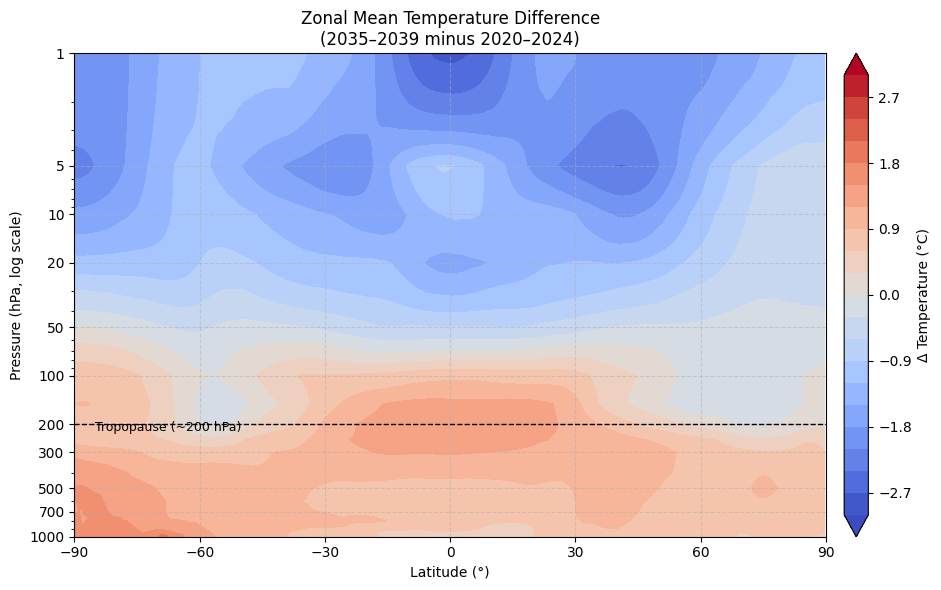

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Extract axes
latitudes = zonal_mean_delta_t.lat
pressures = zonal_mean_delta_t.isobaricInhPa
delta_temp = zonal_mean_delta_t.values  # Already in Â°C

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))

cf = ax.contourf(
    latitudes, pressures, delta_temp,
    levels=np.linspace(-3, 3, 21),
    cmap='coolwarm', extend='both'
)

# Invert pressure axis (top = high altitude)
ax.invert_yaxis()
ax.set_yscale('log')

# Customize ticks and labels
ax.set_yticks([1000, 700, 500, 300, 200, 100, 50, 20, 10, 5, 1])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_ylabel("Pressure (hPa, log scale)", fontsize=10)
ax.set_xlabel("Latitude (Â°)", fontsize=10)
ax.set_xticks(np.arange(-90, 91, 30))

# Add tropopause line
ax.axhline(y=200, color='k', linestyle='--', linewidth=1)
ax.text(-85, 220, "Tropopause (~200 hPa)", fontsize=9, color='k')

# Colorbar
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label("Î” Temperature (Â°C)", fontsize=10)

# Title and grid
ax.set_title("Zonal Mean Temperature Difference\n(2035â€“2039 minus 2020â€“2024)", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Trop vs Strat

In [6]:
### Load Datasets

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Load the two climatology periods
first = xr.open_dataset(f'{PROJ2559_DIR}/pl_dy/ana_var_tem/first_5yr_mean_t_2020_2024.nc')
last = xr.open_dataset(f'{PROJ2559_DIR}/pl_dy/ana_var_tem/last_5yr_mean_t_2035_2039.nc')

# Check their structure
print("First period dataset:")
print(first)
print("\nLast period dataset:")
print(last)

# Print shapes of temperature data
print("\nShape of first.t:", first.t.shape)
print("Shape of last.t:", last.t.shape)


First period dataset:
<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    t              (isobaricInhPa, values) float32 ...

Last period dataset:
<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    t              (isobaricInhPa, values) float32 ...

Shape of first.t: (25, 196608)
Shape of last.t: (25, 196608)


In [7]:
# Extract latitude values for both datasets

lat_values_first = first.latitude.values
lat_values_last = last.latitude.values

# Check latitude distributions
print("First period latitudes:")
print("Shape:", lat_values_first.shape)
print("Unique count:", len(np.unique(lat_values_first)))
print("Sample (first 10):", np.round(lat_values_first[:10], 4))

print("\nLast period latitudes:")
print("Shape:", lat_values_last.shape)
print("Unique count:", len(np.unique(lat_values_last)))
print("Sample (first 10):", np.round(lat_values_last[:10], 4))

# Verify latitude values match between datasets
assert np.array_equal(lat_values_first, lat_values_last), "Latitude values differ between datasets"

First period latitudes:
Shape: (196608,)
Unique count: 511
Sample (first 10): [0.2984 0.5968 0.5968 0.8953 0.8953 1.1937 1.1937 1.4922 0.8953 1.1937]

Last period latitudes:
Shape: (196608,)
Unique count: 511
Sample (first 10): [0.2984 0.5968 0.5968 0.8953 0.8953 1.1937 1.1937 1.4922 0.8953 1.1937]


In [8]:
# Add lat coordinate to enable groupby (for both datasets)

first.coords['lat'] = ('values', first.latitude.values)
last.coords['lat'] = ('values', last.latitude.values)

# Calculate zonal means (group by latitude and average over all longitudes)
first_zonal = first.t.groupby('lat').mean(dim='values')
last_zonal = last.t.groupby('lat').mean(dim='values')

# Verify shapes
print("\nFirst zonal mean shape (pressure x latitude):", first_zonal.shape)
print("Last zonal mean shape (pressure x latitude):", last_zonal.shape)

# Print samples
print("\nFirst zonal mean sample:")
print(first_zonal)
print("\nLast zonal mean sample:")
print(last_zonal)


First zonal mean shape (pressure x latitude): (25, 511)
Last zonal mean shape (pressure x latitude): (25, 511)

First zonal mean sample:
<xarray.DataArray 't' (isobaricInhPa: 25, lat: 511)>
array([[250.7854 , 251.01685, 251.33788, ..., 260.7217 , 260.71808,
        260.71423],
       [249.58029, 249.81062, 250.13011, ..., 260.72986, 260.7257 ,
        260.7196 ],
       [248.3499 , 248.5791 , 248.89703, ..., 260.84634, 260.84448,
        260.8456 ],
       ...,
       [220.42172, 220.43031, 220.43793, ..., 222.17212, 222.1647 ,
        222.16853],
       [234.82315, 234.82642, 234.82597, ..., 233.52074, 233.52191,
        233.51738],
       [258.96652, 258.96133, 258.9796 , ..., 255.1408 , 255.138  ,
        255.12784]], dtype=float32)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
  * lat            (lat) float64 -89.63 -89.27 -88.9 -88.54 ... 88.9 89.27 89.63

Last zonal mean sample:
<xarray.DataArray

In [9]:
# mass-weighted vertical averaging

def mass_weighted_integral(da, pmin, pmax):
    """Calculate mass-weighted vertical average between pressure bounds"""
    # Select pressure levels within bounds
    p_levels = da.isobaricInhPa
    mask = (p_levels >= pmin) & (p_levels <= pmax)
    da_layer = da.where(mask, drop=True)
    
    # Get pressure thickness (Î”p) - using midpoint differences
    p_values = da_layer.isobaricInhPa.values
    dp = np.zeros_like(p_values)
    dp[0] = p_values[0] - p_values[1]  # Top level
    dp[-1] = p_values[-2] - p_values[-1]  # Bottom level
    dp[1:-1] = (p_values[:-2] - p_values[2:])/2  # Mid-levels
    
    # Create xarray DataArray for dp
    dp_da = xr.DataArray(dp, dims=['isobaricInhPa'], 
                        coords={'isobaricInhPa': da_layer.isobaricInhPa})
    
    # Mass-weighted average
    weighted_sum = (da_layer * dp_da).sum(dim='isobaricInhPa')
    total_weight = dp_da.sum(dim='isobaricInhPa')
    return weighted_sum / total_weight

# Calculate mass-weighted averages for both periods
first_tropo = mass_weighted_integral(first_zonal, 200, 1000)
first_strato = mass_weighted_integral(first_zonal, 1, 50)
last_tropo = mass_weighted_integral(last_zonal, 200, 1000)
last_strato = mass_weighted_integral(last_zonal, 1, 50)

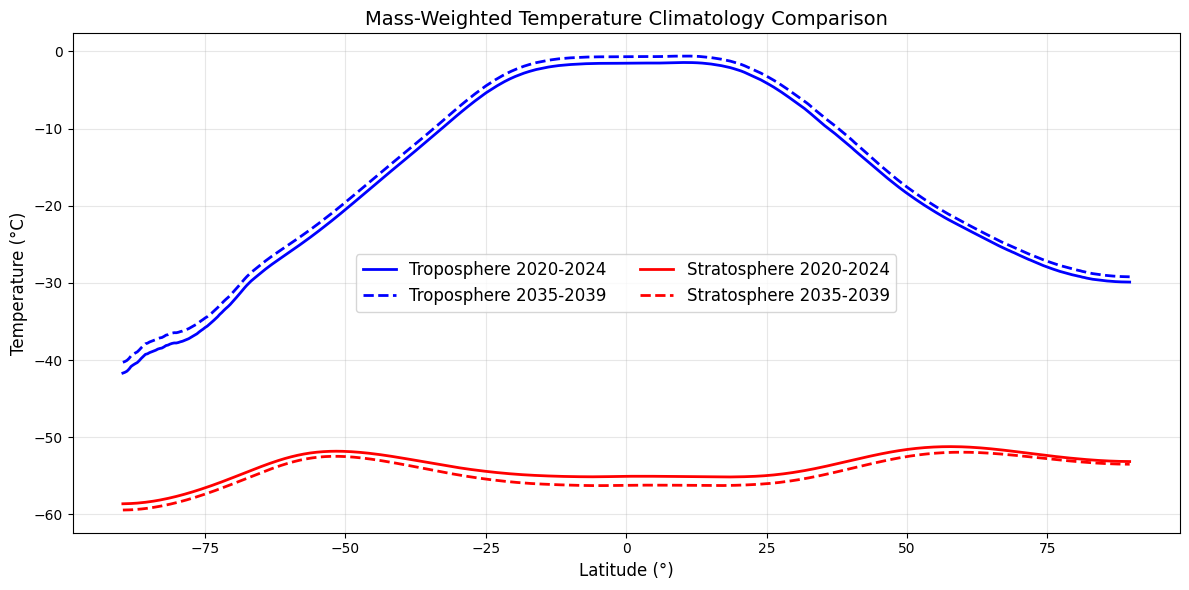

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Plot troposphere comparison
plt.plot(first_tropo.lat, first_tropo - 273.15, 'b-', label='Troposphere 2020-2024', lw=2)
plt.plot(last_tropo.lat, last_tropo - 273.15, 'b--', label='Troposphere 2035-2039', lw=2)

# Plot stratosphere comparison
plt.plot(first_strato.lat, first_strato - 273.15, 'r-', label='Stratosphere 2020-2024', lw=2)
plt.plot(last_strato.lat, last_strato - 273.15, 'r--', label='Stratosphere 2035-2039', lw=2)

plt.title('Mass-Weighted Temperature Climatology Comparison', fontsize=14)
plt.xlabel('Latitude (Â°)', fontsize=12)
plt.ylabel('Temperature (Â°C)', fontsize=12)
plt.legend(fontsize=12, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Optional: Print key statistics
print("Tropospheric warming (2035-2039 vs 2020-2024):", (last_tropo - first_tropo).mean().values)
print("Stratospheric change:", (last_strato - first_strato).mean().values)

Tropospheric warming (2035-2039 vs 2020-2024): 0.9130930104614873
Stratospheric change: -0.8719324659771155


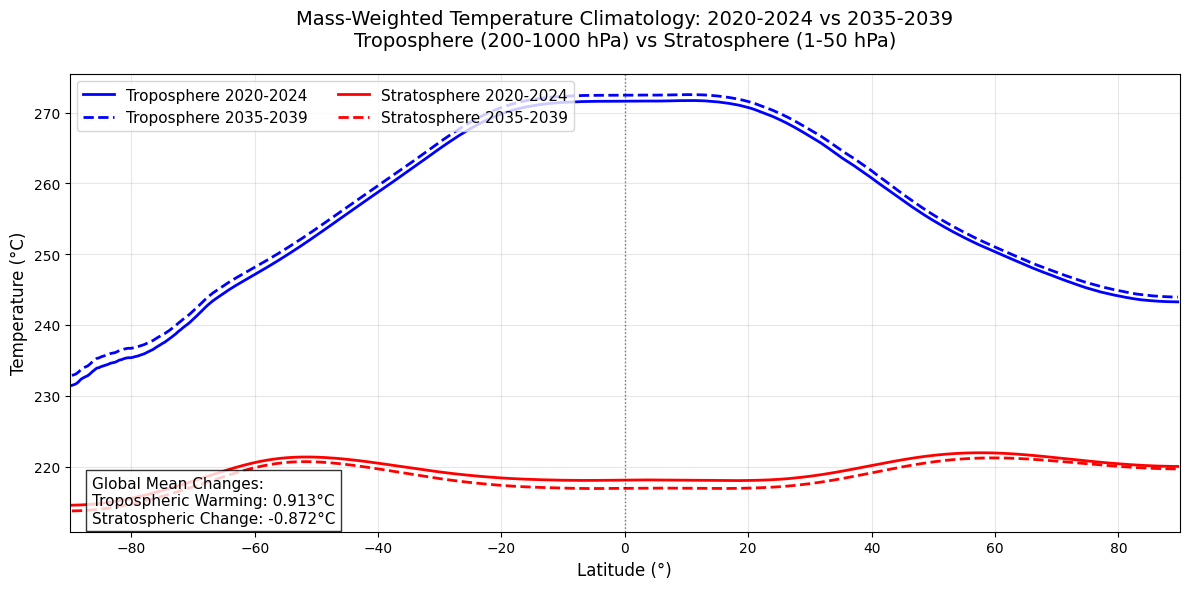

In [15]:
plt.figure(figsize=(12, 6))

# Calculate differences
tropo_diff = (last_tropo - first_tropo).mean().values
strato_diff = (last_strato - first_strato).mean().values

# Plot troposphere comparison
plt.plot(first_tropo.lat, first_tropo, 'b-', label='Troposphere 2020-2024', lw=2)
plt.plot(last_tropo.lat, last_tropo, 'b--', label='Troposphere 2035-2039', lw=2)

# Plot stratosphere comparison
plt.plot(first_strato.lat, first_strato, 'r-', label='Stratosphere 2020-2024', lw=2)
plt.plot(last_strato.lat, last_strato, 'r--', label='Stratosphere 2035-2039', lw=2)

# Add statistics text
stats_text = (f"Global Mean Changes:\n"
              f"Tropospheric Warming: {tropo_diff:.3f}Â°C\n"
              f"Stratospheric Change: {strato_diff:.3f}Â°C")
plt.text(0.02, 0.02, stats_text, transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', alpha=0.8), fontsize=11)

# Set plot properties
plt.title('Mass-Weighted Temperature Climatology: 2020-2024 vs 2035-2039\n'
          'Troposphere (200-1000 hPa) vs Stratosphere (1-50 hPa)', fontsize=14, pad=20)
plt.xlabel('Latitude (Â°)', fontsize=12)
plt.ylabel('Temperature (Â°C)', fontsize=12)
plt.xlim(-90, 90)  # Ensure full latitude range
plt.legend(fontsize=11, ncol=2, loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Add equator line
plt.axvline(0, color='k', linestyle=':', alpha=0.5, linewidth=1)

plt.show()

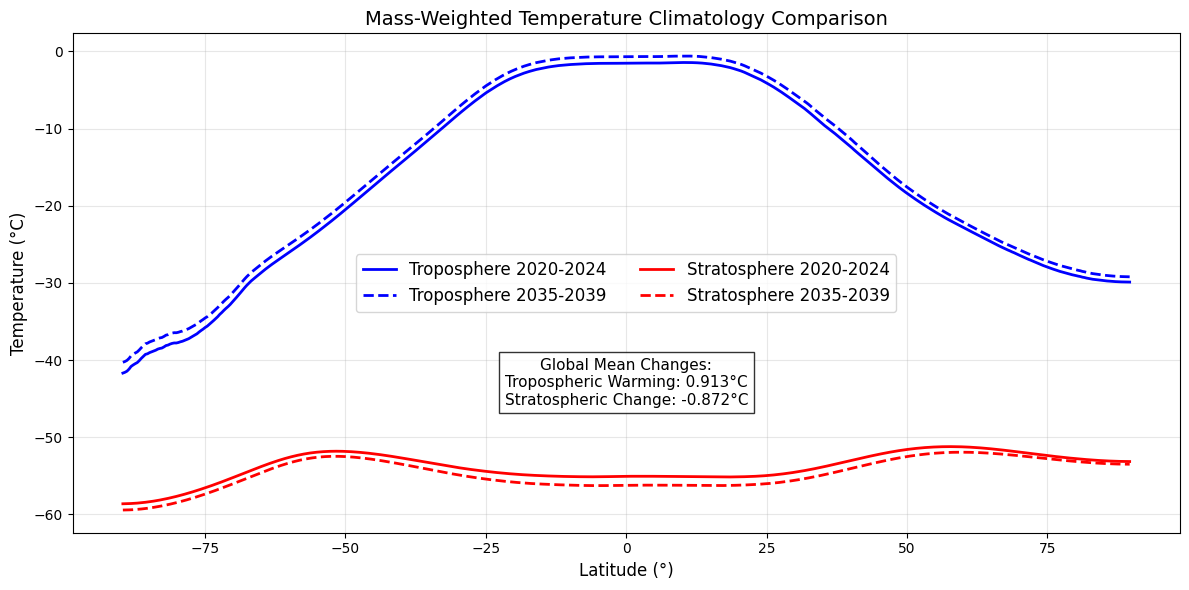

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Calculate differences (convert to Celsius first)
tropo_diff = (last_tropo - first_tropo).mean().values
strato_diff = (last_strato - first_strato).mean().values

# Plot troposphere comparison
plt.plot(first_tropo.lat, first_tropo - 273.15, 'b-', label='Troposphere 2020-2024', lw=2)
plt.plot(last_tropo.lat, last_tropo - 273.15, 'b--', label='Troposphere 2035-2039', lw=2)

# Plot stratosphere comparison
plt.plot(first_strato.lat, first_strato - 273.15, 'r-', label='Stratosphere 2020-2024', lw=2)
plt.plot(last_strato.lat, last_strato - 273.15, 'r--', label='Stratosphere 2035-2039', lw=2)

# Add statistics text at the middle
stats_text = (f"Global Mean Changes:\n"
              f"Tropospheric Warming: {tropo_diff:.3f}Â°C\n"
              f"Stratospheric Change: {strato_diff:.3f}Â°C")
plt.text(0.5, 0.3, stats_text, transform=plt.gca().transAxes,
         ha='center', va='center',
         bbox=dict(facecolor='white', alpha=0.8), fontsize=11)

plt.title('Mass-Weighted Temperature Climatology Comparison', fontsize=14)
plt.xlabel('Latitude (Â°)', fontsize=12)
plt.ylabel('Temperature (Â°C)', fontsize=12)
plt.legend(fontsize=12, ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Trend

In [19]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import os

# Configuration
annual_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_tem/"
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_tem/"
os.makedirs(output_dir, exist_ok=True)

# Load all annual temperature files
years = range(2020, 2040)
ds_list = []

for year in years:
    file = os.path.join(annual_dir, f"annual_mean_t_all_levels_{year}.nc")  # Changed to temperature files
    ds = xr.open_dataset(file)
    ds['year'] = year  # Add year coordinate
    ds_list.append(ds)

# Combine into single dataset
full_ds = xr.concat(ds_list, dim='year')

# Add proper latitude coordinate if needed
if 'lat' not in full_ds.coords:
    full_ds.coords['lat'] = ('values', full_ds.latitude.values)

In [20]:
### Trend Calculation (Temperature)

# Calculate linear trends at each pressure level and latitude
def calculate_trend(y, x):
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    return slope  # Trend per year

# Convert to pandas DataFrame for efficient computation
df = full_ds.t.to_dataframe().reset_index()

# Group by pressure level and latitude (or 'values' if needed)
grouped = df.groupby(['isobaricInhPa', 'lat'])

# Calculate trends
trends = grouped.apply(
    lambda g: calculate_trend(g['t'], g['year'])
).to_xarray().rename('t_trend')

# Convert back to clean xarray Dataset
trends_ds = trends.to_dataset()
trends_ds.attrs['units'] = 'Â°C/year'
trends_ds.attrs['description'] = 'Temperature linear trends (2020-2039)'

# Save the trends
trends_ds.to_netcdf(os.path.join(output_dir, 'temperature_trends_2020-2039.nc'))

In [2]:
trend_ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_tem/temperature_trends_2020-2039.nc")
trend_ds

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, lat: 511)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 1.0 5.0 10.0 ... 950.0 975.0 1e+03
  * lat            (lat) float64 -89.63 -89.27 -88.9 -88.54 ... 88.9 89.27 89.63
Data variables:
    t_trend        (isobaricInhPa, lat) float64 ...
Attributes:
    units:        Â°C/year
    description:  Temperature linear trends (2020-2039)

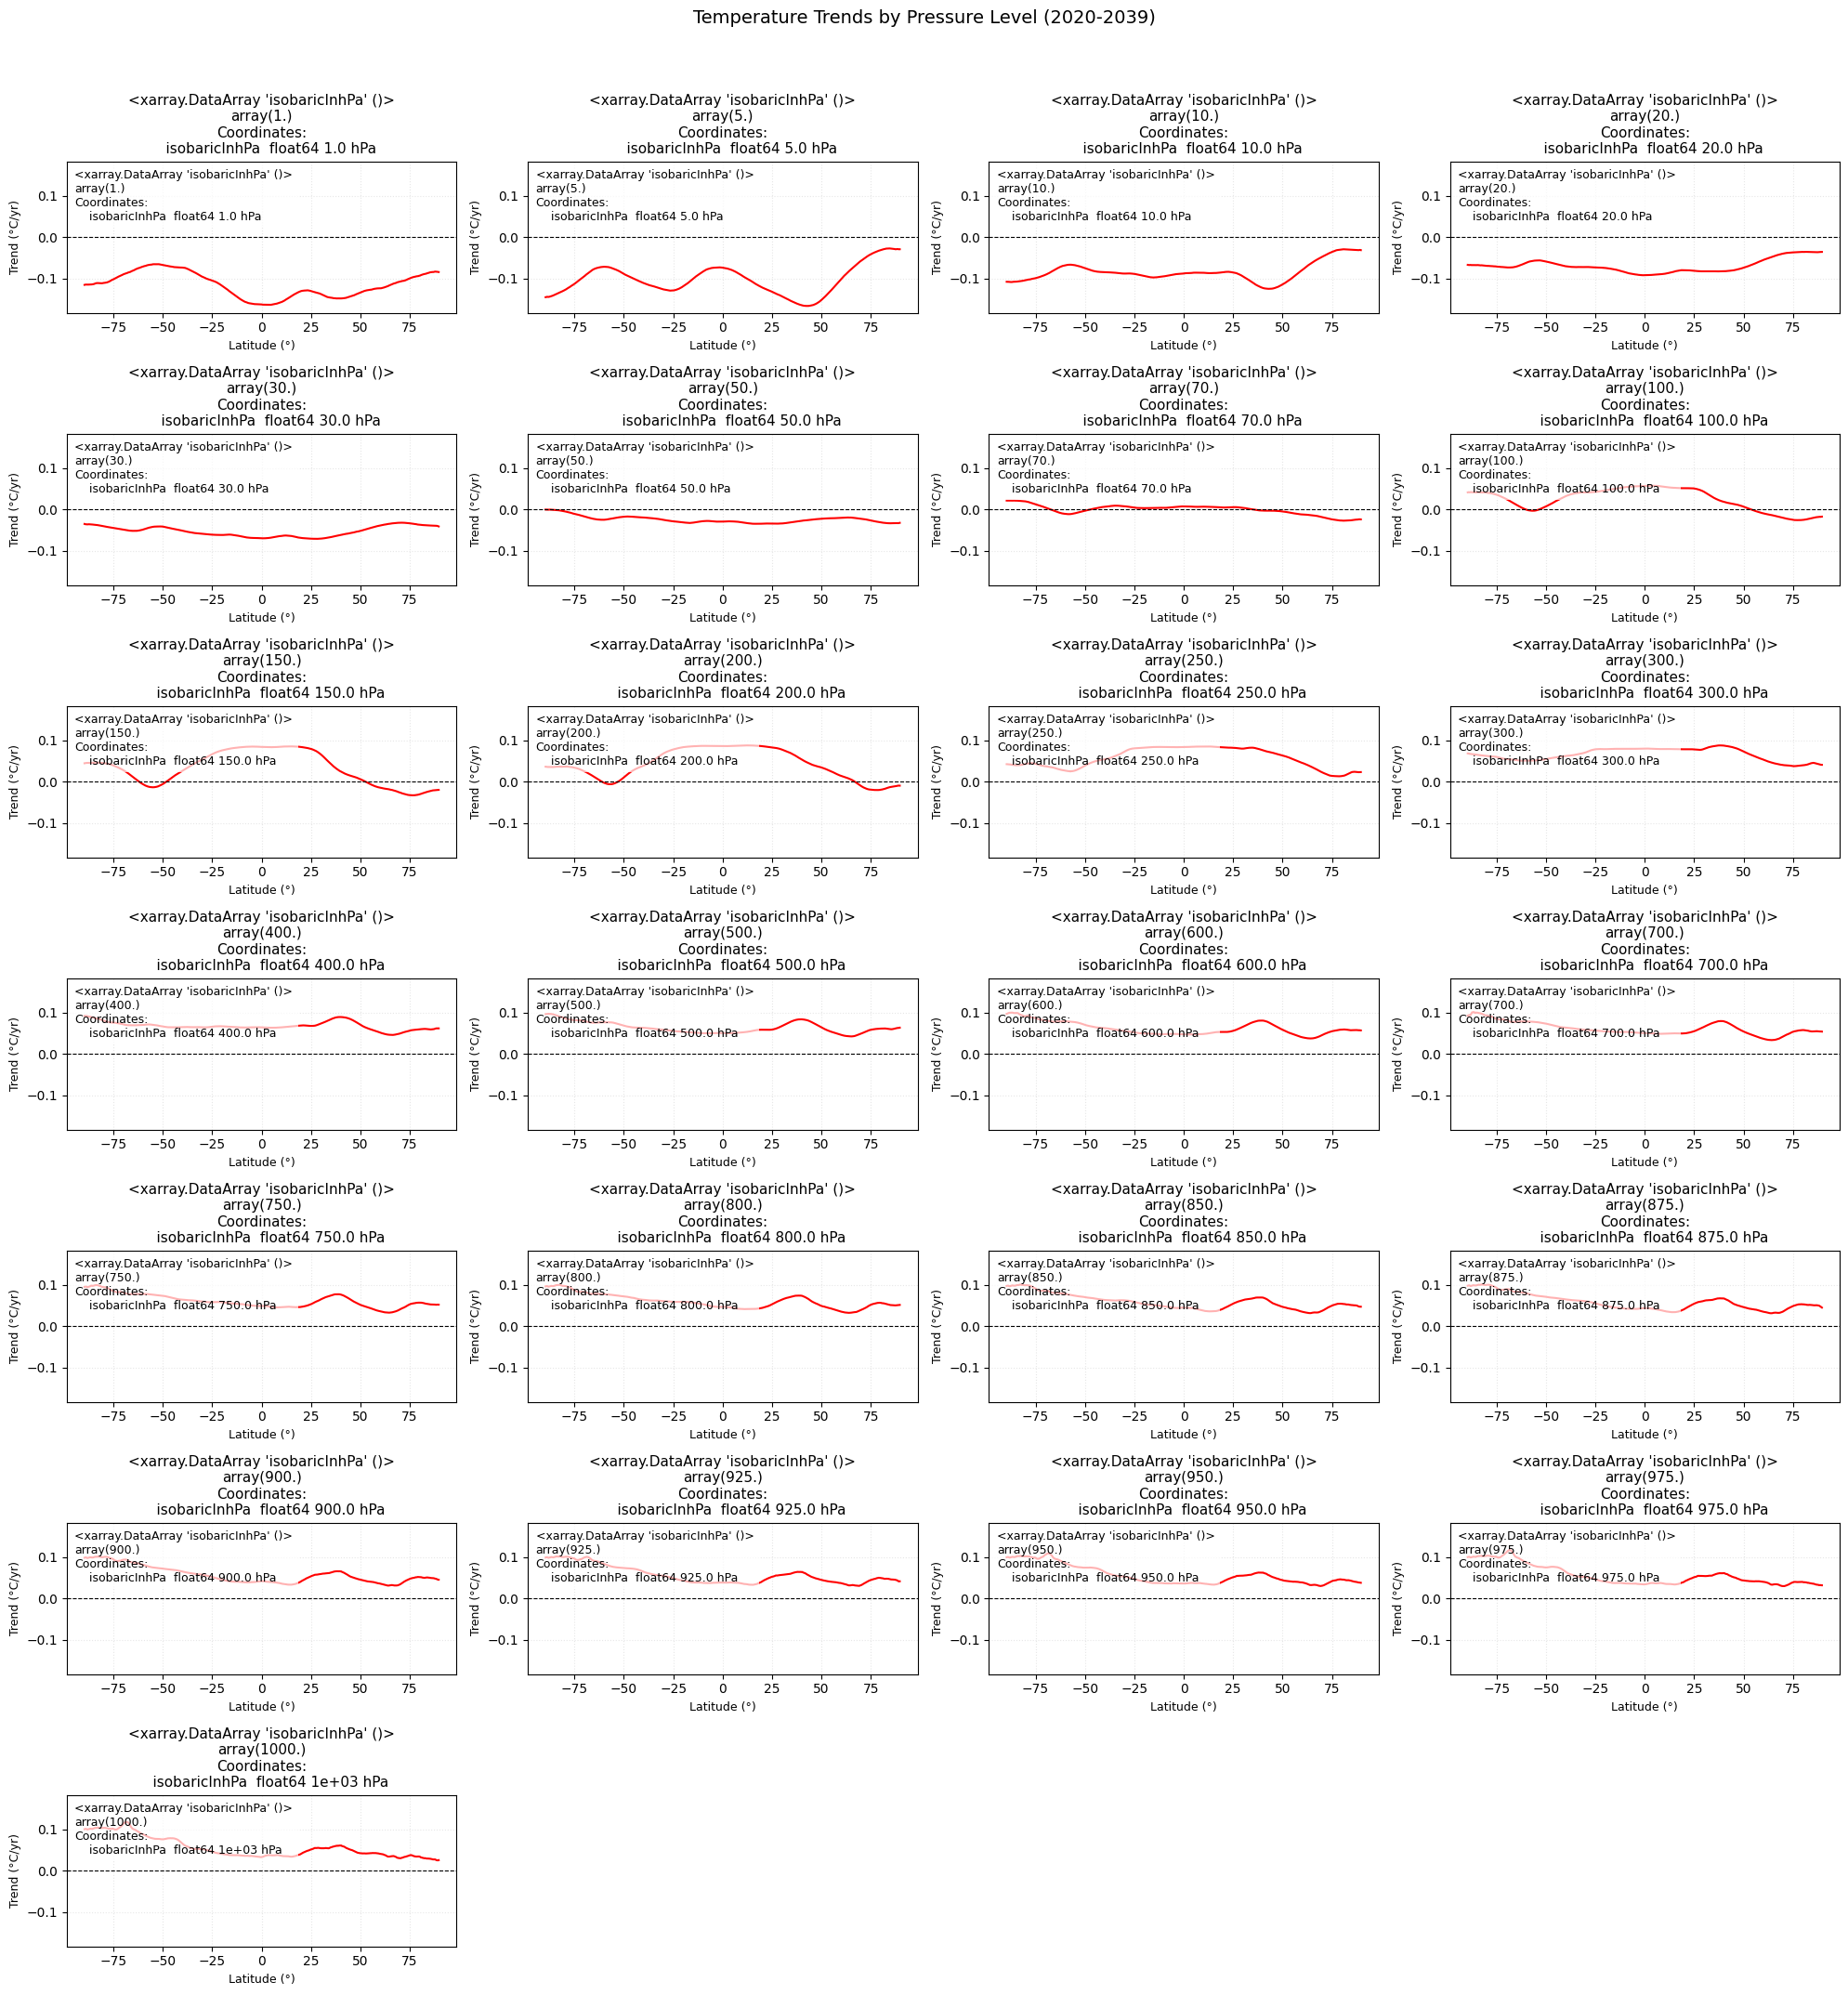

In [21]:
# Create subplot grid for pressure level trends (Temperature)

trend_ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_tem/temperature_trends_2020-2039.nc")

pressure_levels = trends_ds.isobaricInhPa
n_levels = len(pressure_levels)

# Calculate grid dimensions
ncols = 4  # Adjust number of columns as needed
nrows = int(np.ceil(n_levels / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 3*nrows))
axes = axes.flatten()

# Find global max trend for consistent y-axis scaling
global_max = np.max(np.abs(trends_ds.t_trend.values))  # Changed to t_trend

for i, (ax, p) in enumerate(zip(axes, pressure_levels)):
    p_trend = trends_ds.t_trend.sel(isobaricInhPa=p)  # Changed to t_trend
    
    # Main plot (changed line color to red)
    ax.plot(p_trend.lat, p_trend, 'r-', linewidth=1.5)  # 'b-' â†’ 'r-'
    ax.axhline(0, color='k', linestyle='--', linewidth=0.8)
    
    # Formatting (updated units)
    ax.set_title(f'{p} hPa', fontsize=11)
    ax.set_xlabel('Latitude (Â°)', fontsize=9)
    ax.set_ylabel('Trend (Â°C/yr)', fontsize=9)  # m/s â†’ Â°C
    ax.grid(True, linestyle=':', alpha=0.3)
    ax.set_ylim(-global_max*1.1, global_max*1.1)
    
    # Add pressure label
    ax.text(0.02, 0.95, f'{p} hPa', transform=ax.transAxes, 
            fontsize=9, va='top', ha='left', 
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

# Hide empty subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Common title (updated)
plt.suptitle('Temperature Trends by Pressure Level (2020-2039)', y=1.02, fontsize=14)  # Updated title
plt.tight_layout()
plt.show()

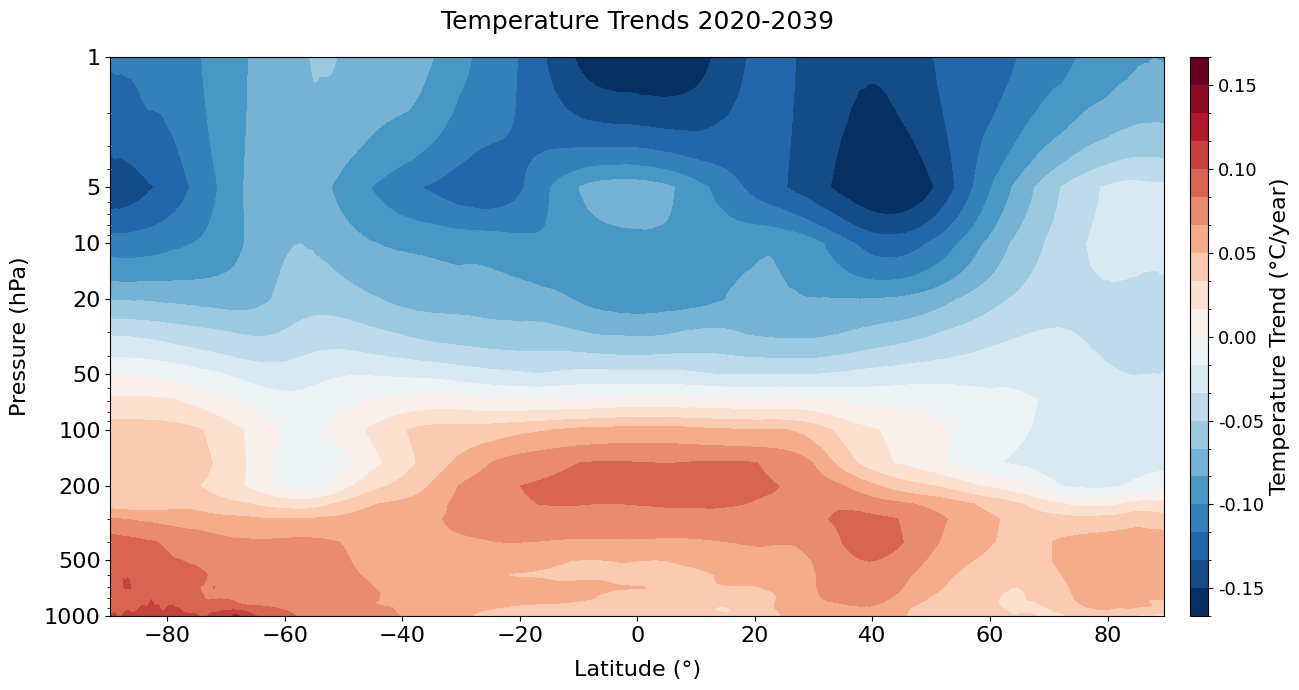

In [23]:
# 2D contour plot of temperature trends

import matplotlib.ticker

plt.figure(figsize=(14, 7))

# Create contour levels symmetric around zero
max_trend = np.max(np.abs(trends_ds.t_trend.values))
levels = np.linspace(-max_trend, max_trend, 21)

# Plot
contour = trends_ds.t_trend.plot.contourf(
    x='lat',
    y='isobaricInhPa',
    levels=levels,
    cmap='RdBu_r',
    add_colorbar=True,
    cbar_kwargs={
        'label': 'Temperature Trend (Â°C/year)',
        'orientation': 'vertical',
        'pad': 0.02,
        'aspect': 30
    }
)

# Formatting
plt.yscale('log')
plt.gca().invert_yaxis()
plt.title('Temperature Trends 2020-2039', pad=20, fontsize=18)  # Increased from 14
plt.xlabel('Latitude (Â°)', labelpad=10, fontsize=16)  # Added fontsize
plt.ylabel('Pressure (hPa)', labelpad=10, fontsize=16)  # Added fontsize

# Improve tick labels
plt.yticks([1000, 500, 200, 100, 50, 20, 10, 5, 1], 
           ['1000', '500', '200', '100', '50', '20', '10', '5', '1'],
           fontsize=16)  # Added fontsize
plt.xticks(fontsize=16)  # Added fontsize

# Colorbar adjustments
cbar = contour.colorbar
cbar.set_label('Temperature Trend (Â°C/year)', fontsize=16)  # Added fontsize
cbar.formatter = matplotlib.ticker.FormatStrFormatter('%.2f')  # 2 decimal places
cbar.ax.tick_params(labelsize=13)  # Added fontsize

#plt.grid(True, linestyle='--', alpha=0.3, which='both')
plt.tight_layout()
plt.show()

### Troposphere vs. Stratosphere Trends

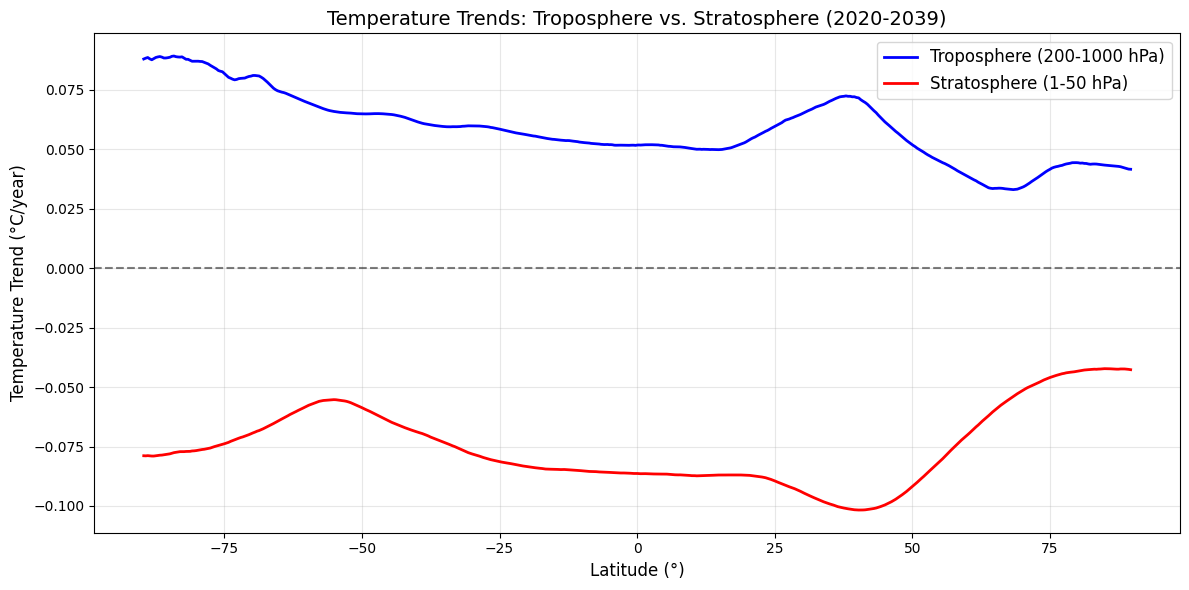

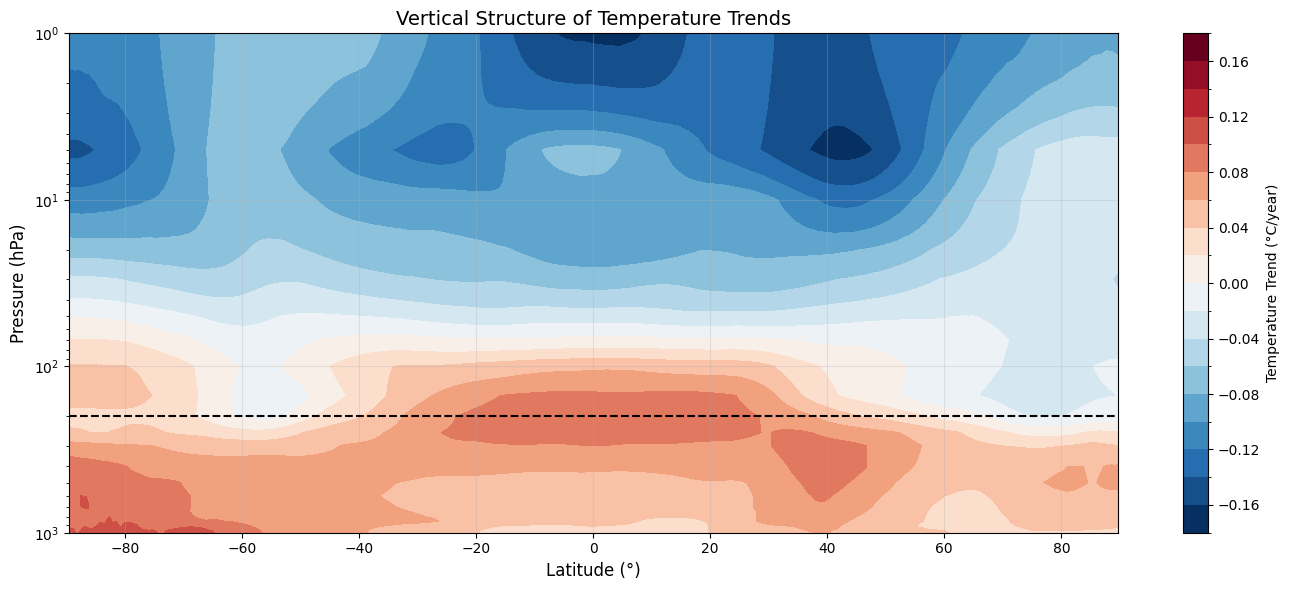

=== Tropospheric Trends ===
Global mean: 0.058 Â°C/year
Max warming: 0.089 Â°C/year at -84.14973293629664Â°
Max cooling: 0.033 Â°C/year at 68.30717609030755Â°

=== Stratospheric Trends ===
Global mean: -0.076 Â°C/year
Max warming: -0.042 Â°C/year at 84.88153790222773Â°
Max cooling: -0.102 Â°C/year at 40.2281847280611Â°


In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Load the temperature trends file
trends_ds = xr.open_dataset(f'{PROJ2559_DIR}/pl_dy/ana_var_tem/temperature_trends_2020-2039.nc')

# Define atmospheric layers
troposphere = trends_ds.where((trends_ds.isobaricInhPa >= 200) & (trends_ds.isobaricInhPa <= 1000), drop=True)
stratosphere = trends_ds.where((trends_ds.isobaricInhPa >= 1) & (trends_ds.isobaricInhPa <= 50), drop=True)

# Calculate mean trends for each layer
troposphere_mean = troposphere.t_trend.mean(dim='isobaricInhPa')
stratosphere_mean = stratosphere.t_trend.mean(dim='isobaricInhPa')

# Plot comparison
plt.figure(figsize=(12, 6))
plt.plot(troposphere_mean.lat, troposphere_mean, 'b-', label='Troposphere (200-1000 hPa)', lw=2)
plt.plot(stratosphere_mean.lat, stratosphere_mean, 'r-', label='Stratosphere (1-50 hPa)', lw=2)

plt.axhline(0, color='k', linestyle='--', alpha=0.5)
plt.title('Temperature Trends: Troposphere vs. Stratosphere (2020-2039)', fontsize=14)
plt.xlabel('Latitude (Â°)', fontsize=12)
plt.ylabel('Temperature Trend (Â°C/year)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Additional diagnostics: Pressure-latitude cross-section of trends
plt.figure(figsize=(14, 6))
trends_ds.t_trend.plot.contourf(
    x='lat',
    y='isobaricInhPa',
    levels=21,
    cmap='RdBu_r',
    cbar_kwargs={'label': 'Temperature Trend (Â°C/year)'}
)
plt.axhline(200, color='k', linestyle='--', label='Tropopause Boundary')
plt.yscale('log')
plt.gca().invert_yaxis()
plt.title('Vertical Structure of Temperature Trends', fontsize=14)
plt.xlabel('Latitude (Â°)', fontsize=12)
plt.ylabel('Pressure (hPa)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print key statistics
print("=== Tropospheric Trends ===")
print(f"Global mean: {troposphere_mean.mean().values:.3f} Â°C/year")
print(f"Max warming: {troposphere_mean.max().values:.3f} Â°C/year at {troposphere_mean.lat[troposphere_mean.argmax()].values}Â°")
print(f"Max cooling: {troposphere_mean.min().values:.3f} Â°C/year at {troposphere_mean.lat[troposphere_mean.argmin()].values}Â°")

print("\n=== Stratospheric Trends ===")
print(f"Global mean: {stratosphere_mean.mean().values:.3f} Â°C/year")
print(f"Max warming: {stratosphere_mean.max().values:.3f} Â°C/year at {stratosphere_mean.lat[stratosphere_mean.argmax()].values}Â°")
print(f"Max cooling: {stratosphere_mean.min().values:.3f} Â°C/year at {stratosphere_mean.lat[stratosphere_mean.argmin()].values}Â°")

In [3]:
trends_ds

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, lat: 511)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 1.0 5.0 10.0 ... 950.0 975.0 1e+03
  * lat            (lat) float64 -89.63 -89.27 -88.9 -88.54 ... 88.9 89.27 89.63
Data variables:
    t_trend        (isobaricInhPa, lat) float64 -0.1158 -0.1153 ... 0.02536
Attributes:
    units:        Â°C/year
    description:  Temperature linear trends (2020-2039)

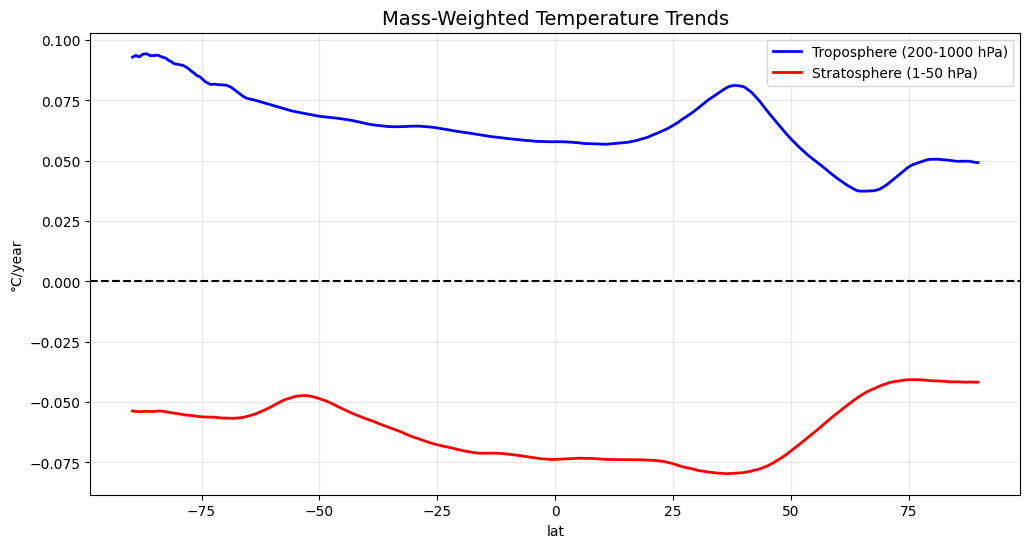

In [3]:
def mass_weighted_integral(ds, var_name, pmin, pmax):
    """Calculate mass-weighted vertical integral between pressure bounds"""
    # Get pressure levels in correct orientation
    p = ds.isobaricInhPa
    mask = (p >= pmin) & (p <= pmax)
    
    # Calculate pressure thickness (Î”p) with proper broadcasting
    p_values = p.values
    dp = np.abs(np.diff(p_values, prepend=p_values[0]+np.diff(p_values)[0]))  # Handle first level
    
    # Create xarray DataArray for dp with proper dimensions
    dp_da = xr.DataArray(dp, dims=['isobaricInhPa'], coords={'isobaricInhPa': p})
    
    # Apply mass weighting
    weighted_trend = ds[var_name].where(mask) * dp_da
    integrated_trend = weighted_trend.sum(dim='isobaricInhPa') / (pmax - pmin)
    
    return integrated_trend

# For temperature trends
troposphere_trend = mass_weighted_integral(trends_ds, 't_trend', 200, 1000)
stratosphere_trend = mass_weighted_integral(trends_ds, 't_trend', 1, 50)

plt.figure(figsize=(12,6))
troposphere_trend.plot(label='Troposphere (200-1000 hPa)', color='b', lw=2)
stratosphere_trend.plot(label='Stratosphere (1-50 hPa)', color='r', lw=2)
plt.axhline(0, color='k', ls='--')
plt.title('Mass-Weighted Temperature Trends', fontsize=14)
plt.ylabel('Â°C/year')
plt.legend()
plt.grid(True, alpha=0.3)

### Both trends

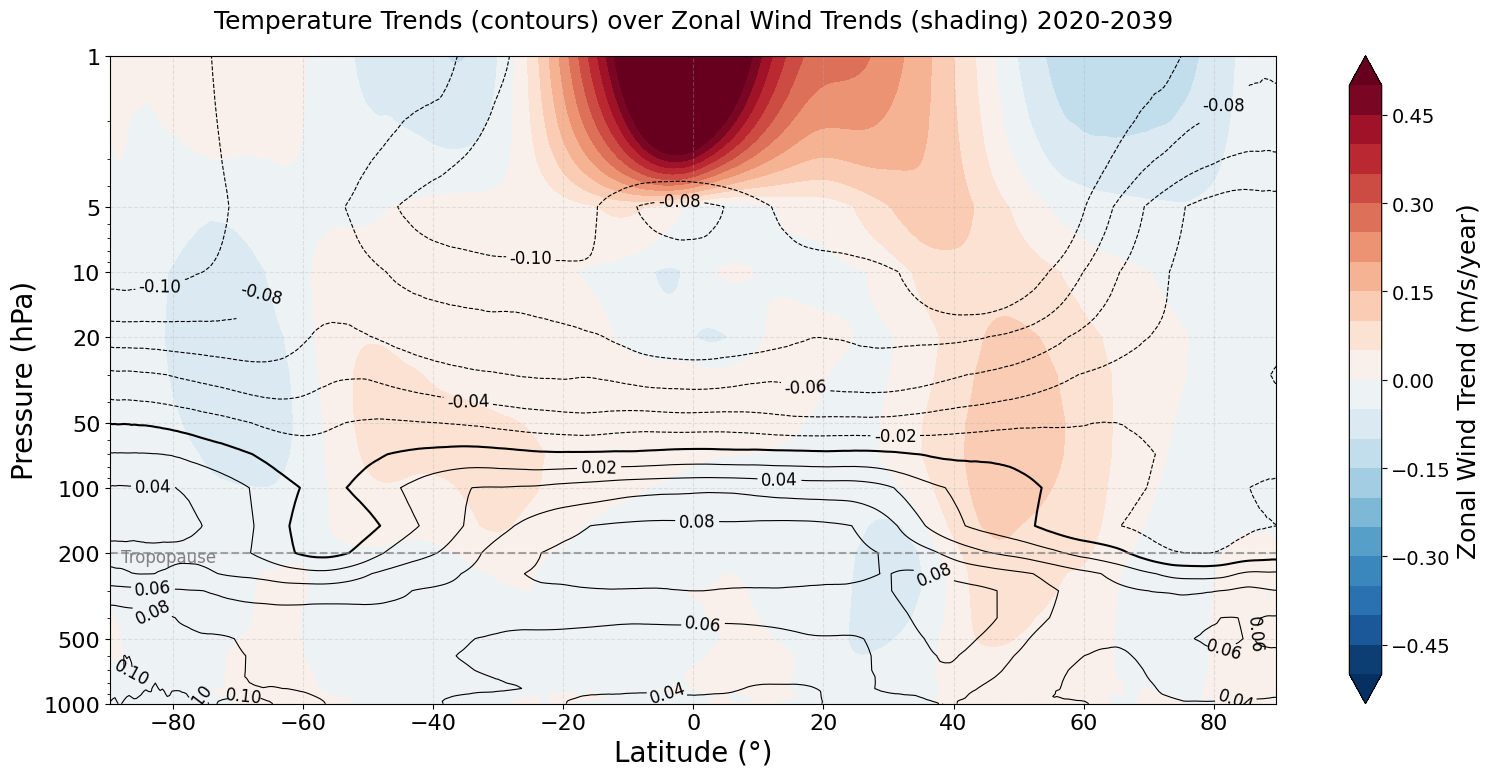

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Load trend datasets
temp_trends = xr.open_dataset(f'{PROJ2559_DIR}/pl_dy/ana_var_tem/temperature_trends_2020-2039.nc')
wind_trends = xr.open_dataset(f'{PROJ2559_DIR}/pl_dy/ana_var_ums/zonal_wind_trends_2020-2039.nc')

# Create figure with larger font sizes
plt.figure(figsize=(16, 8))
plt.rcParams.update({'font.size': 14})  # Base font size

# Plot wind trends (shaded)
cf = plt.contourf(
    wind_trends.lat, 
    wind_trends.isobaricInhPa,
    wind_trends.u_trend,
    levels=np.linspace(-0.5, 0.5, 21),
    cmap='RdBu_r',
    extend='both'
)

# Custom contour line styles
positive_levels = np.linspace(0, 0.1, 6)[1:]  # Exclude zero
negative_levels = np.linspace(-0.1, 0, 6)[:-1]  # Exclude zero

# Positive trends (solid lines)
cs_pos = plt.contour(
    temp_trends.lat,
    temp_trends.isobaricInhPa,
    temp_trends.t_trend,
    levels=positive_levels,
    colors='k',
    linewidths=.8,
    linestyles='-'
)

# Negative trends (dashed lines)
cs_neg = plt.contour(
    temp_trends.lat,
    temp_trends.isobaricInhPa,
    temp_trends.t_trend,
    levels=negative_levels,
    colors='k',
    linewidths=.8,
    linestyles='--'
)

# Zero line (thicker)
cs_zero = plt.contour(
    temp_trends.lat,
    temp_trends.isobaricInhPa,
    temp_trends.t_trend,
    levels=[0],
    colors='k',
    linewidths=1.5,
    linestyles='-'
)

# Label formatting
plt.clabel(cs_pos, inline=True, fontsize=12, fmt='%.2f')
plt.clabel(cs_neg, inline=True, fontsize=12, fmt='%.2f')

# Formatting with larger fonts
plt.yscale('log')
plt.gca().invert_yaxis()
cbar = plt.colorbar(cf)
cbar.set_label('Zonal Wind Trend (m/s/year)', fontsize=18)
cbar.ax.tick_params(labelsize=14)

plt.title('Temperature Trends (contours) over Zonal Wind Trends (shading) 2020-2039', 
          pad=20, fontsize=18)
plt.xlabel('Latitude (Â°)', fontsize=20)
plt.ylabel('Pressure (hPa)', fontsize=20)

# Custom y-ticks as requested
plt.yticks([1000, 500, 200, 100, 50, 20, 10, 5, 1], 
           ['1000', '500', '200', '100', '50', '20', '10', '5', '1'],
           fontsize=16)
plt.xticks(fontsize=16)

# Tropopause reference
plt.axhline(200, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
plt.text(-88, 220, 'Tropopause', fontsize=12, color='gray')

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

## Vertical velocity 'w'

### Check Data

In [1]:
import os
import numpy as np
import xarray as xr
import healpy as hp
import cmocean as cmo
import matplotlib.cm as cm
import matplotlib.pylab as plt

In [5]:
# @ Levante
pathpl_dy_w = f"{PROJ2559_DIR}/pl_dy/tco2559_proj/0001_pl_w_healpix_hourly_2034.grb"
data_pl_dy_w = xr.open_dataset(pathpl_dy_w, engine="cfgrib")
data_pl_dy_w

<xarray.Dataset>
Dimensions:        (time: 365, isobaricInhPa: 25, values: 196608)
Coordinates:
  * time           (time) datetime64[ns] 2034-01-01 2034-01-02 ... 2034-12-31
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
    valid_time     (time) datetime64[ns] ...
Dimensions without coordinates: values
Data variables:
    w              (time, isobaricInhPa, values) float32 ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          1003
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-04-21T18:59 GRIB to CDM+CF via cfgrib-0.9.1...

/tmp/ipykernel_867283/2726134291.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


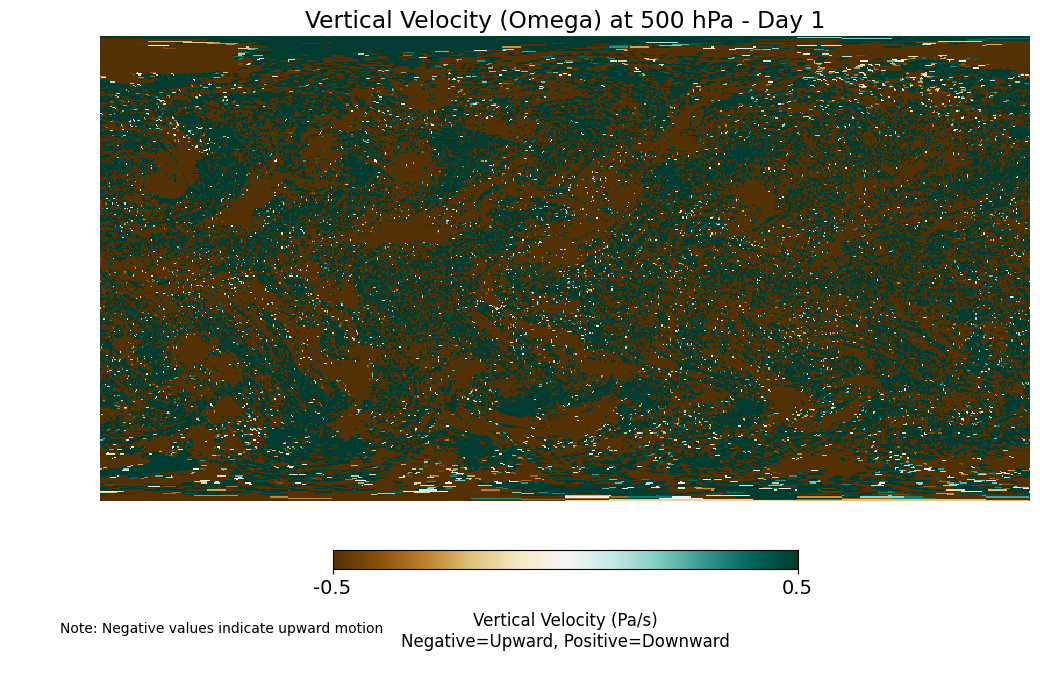

In [8]:
# Select mid-troposphere level (500 hPa) and first timestep
w_midtroposphere = data_pl_dy_w.w.isel(time=0, isobaricInhPa=13)  # Adjust index for 500 hPa level

# Convert to numpy array (negative upward convention)
w_map = -w_midtroposphere.values * 100  # Convert to Pa/s and invert sign

# Plot settings
plt.figure(figsize=(12, 8))

# Plot the map using Healpy's cartview
hp.cartview(
    w_map,
    flip="geo",          # Match geographical coordinates
    nest=True,           # Use NESTED ordering
    lonra=[-180, 180],   # Full longitude range
    latra=[-90, 90],     # Full latitude range
    title="Vertical Velocity (Omega) at 500 hPa - Day 1",
    min=-0.5,            # Custom scale (Pa/s)
    max=0.5,
    cmap="BrBG",         # Brown-Blue-Green for vertical motion
    badcolor="gray",     # Missing data color
    hold=True,
)

# Customize colorbar 
cbar = plt.gcf().axes[-1]
cbar.set_xlabel("Vertical Velocity (Pa/s)\nNegative=Upward, Positive=Downward", 
               fontsize=12, labelpad=10)

# Add important features
plt.annotate("Note: Negative values indicate upward motion",
             xy=(0.05, 0.05), xycoords='figure fraction',
             fontsize=10, color='black')

# Adjust layout
plt.tight_layout()
plt.show()

### Monthly means: Compute and save

In [13]:
import os
import xarray as xr

# Define paths (adjust to your temperature data)
base_path = f"{PROJ2559_DIR}/pl_dy/tco2559_proj/0001_pl_w_healpix_hourly_"  # Temperature files
years = range(2020, 2040)
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_wms/"  # New directory for temperature

#os.makedirs(output_dir, exist_ok=True)

In [3]:
# for year in years:
#     file_path = f"{base_path}{year}.grb"
#     print(f"Processing {year}...")
    
#     with xr.open_dataset(file_path, engine="cfgrib", chunks={"time": 1000}) as ds:
#         # Extract vertical velocity variable (typically 'w' in GRIB)
#         w_velocity = ds['w']  # Changed from 't' to 'w'
        
#         # Monthly means (preserves all levels)
#         monthly_means = w_velocity.groupby("time.month").mean(dim="time").compute()
        
#         # Save
#         output_file = f"{output_dir}monthly_mean_w_all_levels_{year}.nc"
#         monthly_means.to_dataset(name="w").to_netcdf(output_file)

Processing 2033...
Processing 2034...
Processing 2035...
Processing 2036...
Processing 2037...
Processing 2038...
Processing 2039...


In [4]:
# Check one output file
test = xr.open_dataset(f"{output_dir}monthly_mean_w_all_levels_2030.nc")
print(test)

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608, month: 12)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
  * month          (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
Dimensions without coordinates: values
Data variables:
    w              (month, isobaricInhPa, values) float32 ...


### Annual means: Compute and Save

In [14]:
# Concatenate & Add Time Coordinates for Vertical Velocity
datasets_w = []
for year in years:
    ds = xr.open_dataset(f"{output_dir}monthly_mean_w_all_levels_{year}.nc")
    time = xr.cftime_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=("month", time))  # Add time coordinate
    datasets_w.append(ds)

# Concatenate all years
ds_W = xr.concat(datasets_w, dim="month")

In [15]:
# Compute Annual Means and Save for Vertical Velocity
annual_means_W = ds_W.w.groupby("time.year").mean(dim="month")

# Save annual means
for year in annual_means_W.year.values:
    annual_means_W.sel(year=year).to_dataset(name="w").to_netcdf(
        f"{output_dir}annual_mean_w_all_levels_{year}.nc"
    )

In [17]:
# Long-Term Climatology and Save for Vertical Velocity
climatology_W = annual_means_W.mean(dim="year")
climatology_W.to_dataset(name="w").to_netcdf(
    f"{output_dir}climatology_w_all_levels_2020-2039.nc"
)

### Plot: Climatology

In [18]:
import healpy as hp
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Load climatology data
ds_w = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_wms/climatology_w_all_levels_2020-2039.nc")

# Select 4 levels: 1000, 500, 250, 50 hPa
levels = [1000, 500, 250, 50]
w_data = {level: ds_w.w.sel(isobaricInhPa=level, method="nearest").values for level in levels}

# Create HEALPix grid (with correct resolution based on the dataset)
nside = hp.npix2nside(len(ds_w['w'].values[0]))  # HEALPix resolution
pixel_lats = hp.pix2ang(nside, np.arange(len(ds_w['w'].values[0])), lonlat=True)[1]  # Get latitude in HEALPix order

# Create regular grid from HEALPix latitudes and longitudes
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), np.linspace(-90, 90, 180))

# Interpolate for all levels
grid_W = {}
for level in levels:
    grid_W[level] = np.zeros_like(grid_lat)
    for i in range(grid_lon.shape[0]):
        for j in range(grid_lon.shape[1]):
            grid_W[level][i,j] = hp.get_interp_val(
                np.nan_to_num(w_data[level], nan=0),
                grid_lon[i,j], grid_lat[i,j],
                lonlat=True, nest=True
            )

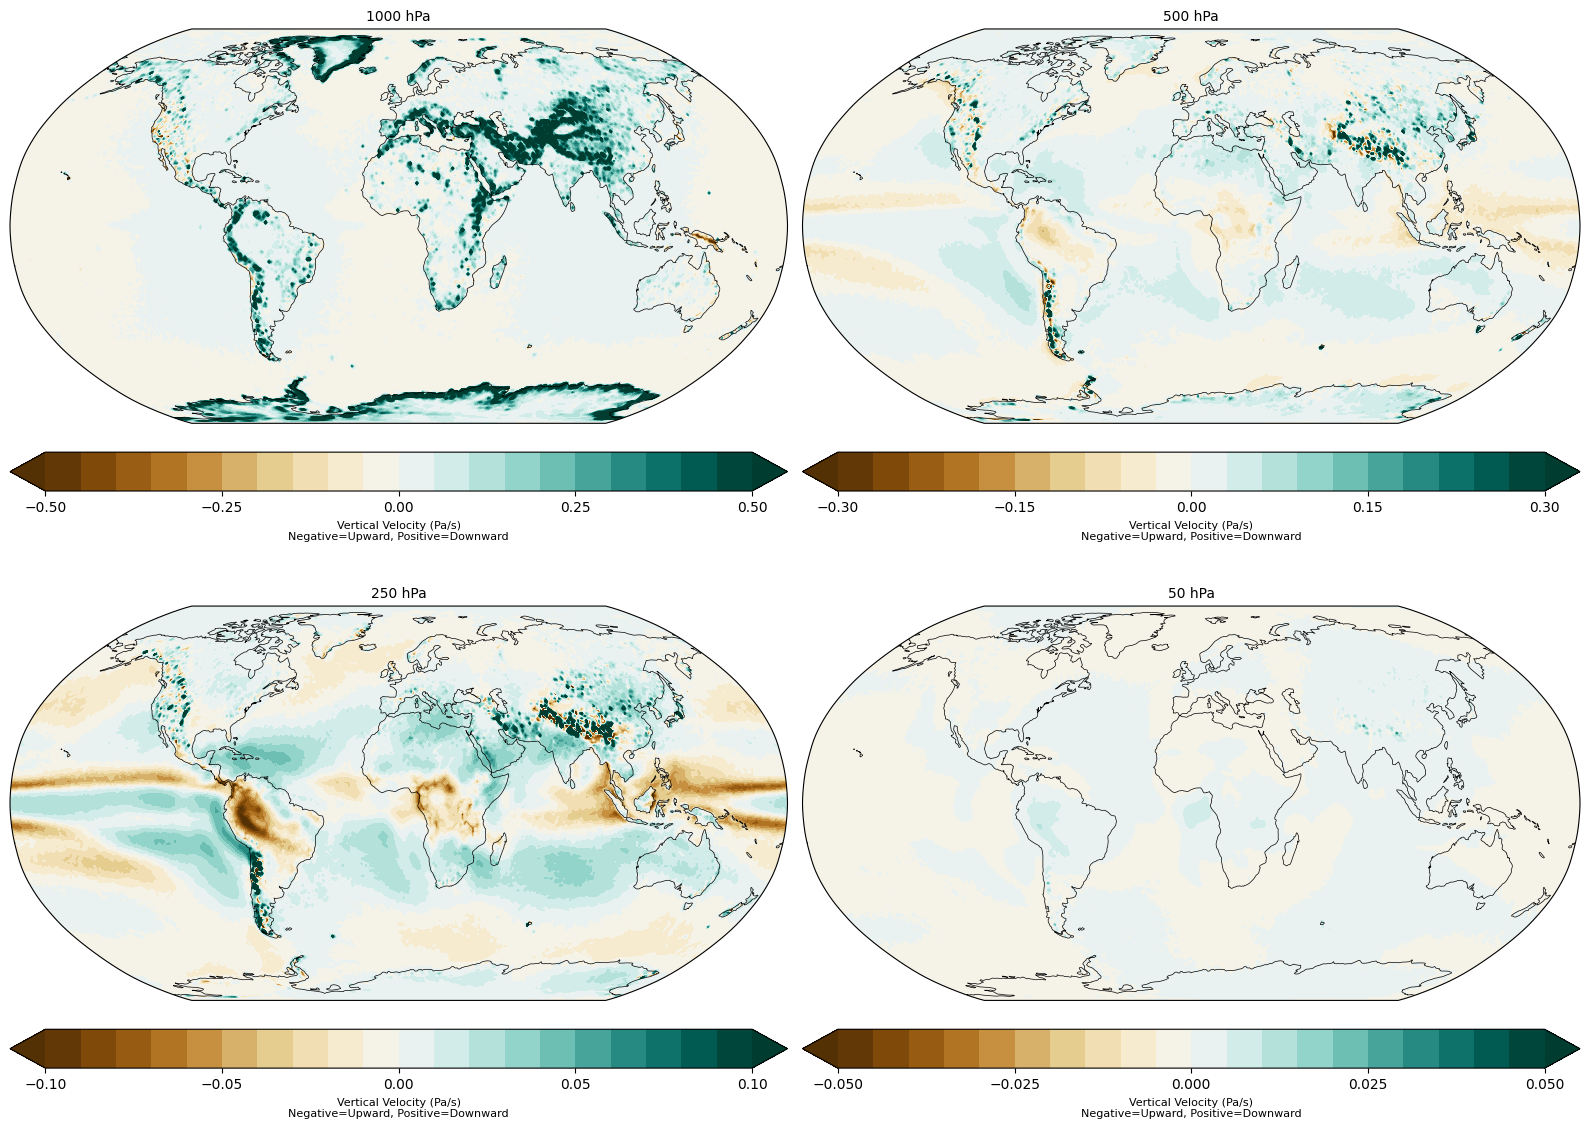

In [19]:
# Plot for each pressure level
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, axes = plt.subplots(2, 2, figsize=(16, 12), subplot_kw={'projection': ccrs.Robinson()})
axes = axes.flatten()

# Define ranges for the colorbar (in Pa/s)
level_ranges = {
    1000: (-0.5, 0.5),
    500: (-0.3, 0.3),
    250: (-0.1, 0.1),
    50: (-0.05, 0.05)
}

for ax, level in zip(axes, levels):
    data = grid_W[level]
    vmin, vmax = level_ranges[level]

    cf = ax.contourf(grid_lon, grid_lat, data, levels=np.linspace(vmin, vmax, 21),
                     cmap='BrBG', transform=ccrs.PlateCarree(), extend='both')
    
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.set_title(f"{level} hPa", fontsize=10)
    
    cbar = fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05)
    cbar.set_ticks(np.linspace(vmin, vmax, 5))
    cbar.set_label("Vertical Velocity (Pa/s)\nNegative=Upward, Positive=Downward", fontsize=8)

plt.tight_layout()
plt.show()

### Zonal Mean

In [20]:
# Load climatology dataset for vertical velocity
ds_w = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_wms/climatology_w_all_levels_2020-2039.nc")

# Quick check of the dimensions and variables
print(ds_w)

<xarray.Dataset>
Dimensions:        (isobaricInhPa: 25, values: 196608)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
    latitude       (values) float64 ...
    longitude      (values) float64 ...
Dimensions without coordinates: values
Data variables:
    w              (isobaricInhPa, values) float32 ...


In [21]:
# Compute Zonal Mean Vertical Velocity

# Add latitude as a coordinate (to enable groupby)
ds_w.coords['lat'] = ('values', ds_w.latitude.values)

# Group by latitude and compute mean over longitude (zonal mean)
zonal_mean_w = ds_w.w.groupby('lat').mean(dim='values')  # dims: (isobaricInhPa, lat)

# Check shape and a sample
print(zonal_mean_w.shape)
print(zonal_mean_w)

(25, 511)
<xarray.DataArray 'w' (isobaricInhPa: 25, lat: 511)>
array([[-1.43341087e-02,  9.42290202e-03, -1.37411505e-02, ...,
         7.60073075e-04,  5.99078776e-04, -1.12416642e-03],
       [-1.43341087e-02,  9.42290388e-03, -1.37411477e-02, ...,
         1.77135912e-03,  9.22889798e-04, -2.95961072e-04],
       [-1.43341133e-02,  9.42289643e-03, -1.37411533e-02, ...,
         1.25425693e-03, -1.27393578e-05,  7.82170158e-04],
       ...,
       [-2.07109424e-05, -1.11728823e-05, -3.12721641e-05, ...,
        -4.53472952e-04, -4.45141981e-04, -4.32774716e-04],
       [ 1.27399471e-05,  1.36310673e-05,  2.98904852e-05, ...,
        -3.48561560e-04, -3.39150632e-04, -3.45715584e-04],
       [-4.84737166e-06, -1.61226526e-05, -5.47924401e-06, ...,
        -1.17787255e-04, -1.29369757e-04, -1.16279509e-04]], dtype=float32)
Coordinates:
    step           timedelta64[ns] ...
  * isobaricInhPa  (isobaricInhPa) float64 1e+03 975.0 950.0 ... 10.0 5.0 1.0
  * lat            (lat) float64 -8

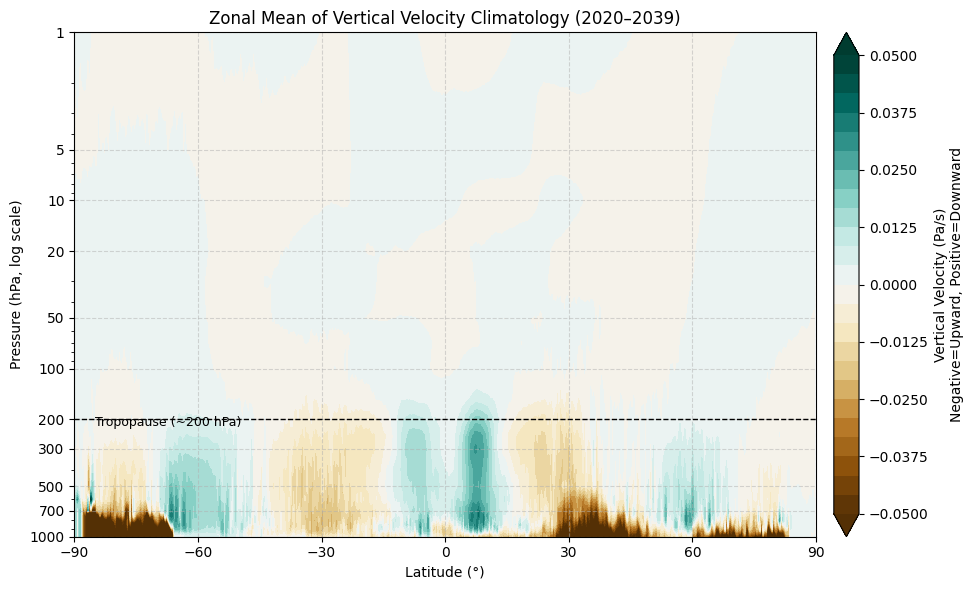

In [22]:
# Plot Zonal Mean Vertical Velocity (Pa/s)

# Set up figure
fig, ax = plt.subplots(figsize=(10, 6))

# Prepare data
lat = zonal_mean_w.lat
pressure = zonal_mean_w.isobaricInhPa
data = zonal_mean_w.values * -1  # Convert to Pa/s and invert sign (negative=upward)

# Create contour plot
cf = ax.contourf(
    lat, pressure, data,
    levels=np.linspace(-0.05, 0.05, 25),  # Adjusted for typical omega values
    cmap='BrBG', extend='both'
)

# Invert y-axis (pressure decreases with height)
ax.invert_yaxis()
ax.set_yscale('log')

# Custom pressure levels
ax.set_yticks([1000, 700, 500, 300, 200, 100, 50, 20, 10, 5, 1])
ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_ylabel("Pressure (hPa, log scale)", fontsize=10)

# Latitude markers
ax.set_xticks(np.arange(-90, 91, 30))
ax.set_xlabel("Latitude (Â°)", fontsize=10)

# Tropopause line (approx. at 200 hPa)
ax.axhline(y=200, color='k', linestyle='--', linewidth=1)
ax.text(-85, 220, "Tropopause (~200 hPa)", fontsize=9, color='k')

# Title and colorbar
ax.set_title("Zonal Mean of Vertical Velocity Climatology (2020â€“2039)", fontsize=12)
cbar = plt.colorbar(cf, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label("Vertical Velocity (Pa/s)\nNegative=Upward, Positive=Downward", fontsize=10)

# Grid
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Trend

In [23]:
import xarray as xr
import numpy as np
import os

# Configuration
annual_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_wms/"  # Changed to omega directory
output_dir = f"{PROJ2559_DIR}/pl_dy/ana_var_wms/"
os.makedirs(output_dir, exist_ok=True)

# Load all annual omega files
years = range(2020, 2040)
ds_list = []

for year in years:
    file = os.path.join(annual_dir, f"annual_mean_w_all_levels_{year}.nc")  # Omega files
    ds = xr.open_dataset(file)
    ds['year'] = year  # Add year coordinate
    ds_list.append(ds)

# Combine into single dataset
full_ds = xr.concat(ds_list, dim='year')

# Add proper latitude coordinate if needed
if 'lat' not in full_ds.coords:
    full_ds.coords['lat'] = ('values', full_ds.latitude.values)

In [24]:
# Trend Calculation (Vertical Velocity)

from scipy import stats
import pandas as pd

# Calculate linear trends
def calculate_trend(y, x):
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    return slope  # Trend per year

# Convert to pandas DataFrame
df = full_ds.w.to_dataframe().reset_index()  # Changed 't' to 'w'

# Group by pressure level and latitude
grouped = df.groupby(['isobaricInhPa', 'lat'])

# Calculate trends
trends = grouped.apply(
    lambda g: calculate_trend(g['w'], g['year'])  # Changed 't' to 'w'
).to_xarray().rename('w_trend')  # Renamed to w_trend

# Convert back to xarray Dataset
trends_ds = trends.to_dataset()
trends_ds.attrs['units'] = 'Pa/s/year'  # Updated units
trends_ds.attrs['description'] = 'Vertical velocity linear trends (2020-2039)'

# Save the trends
trends_ds.to_netcdf(os.path.join(output_dir, 'w_velocity_trends_2020-2039.nc'))

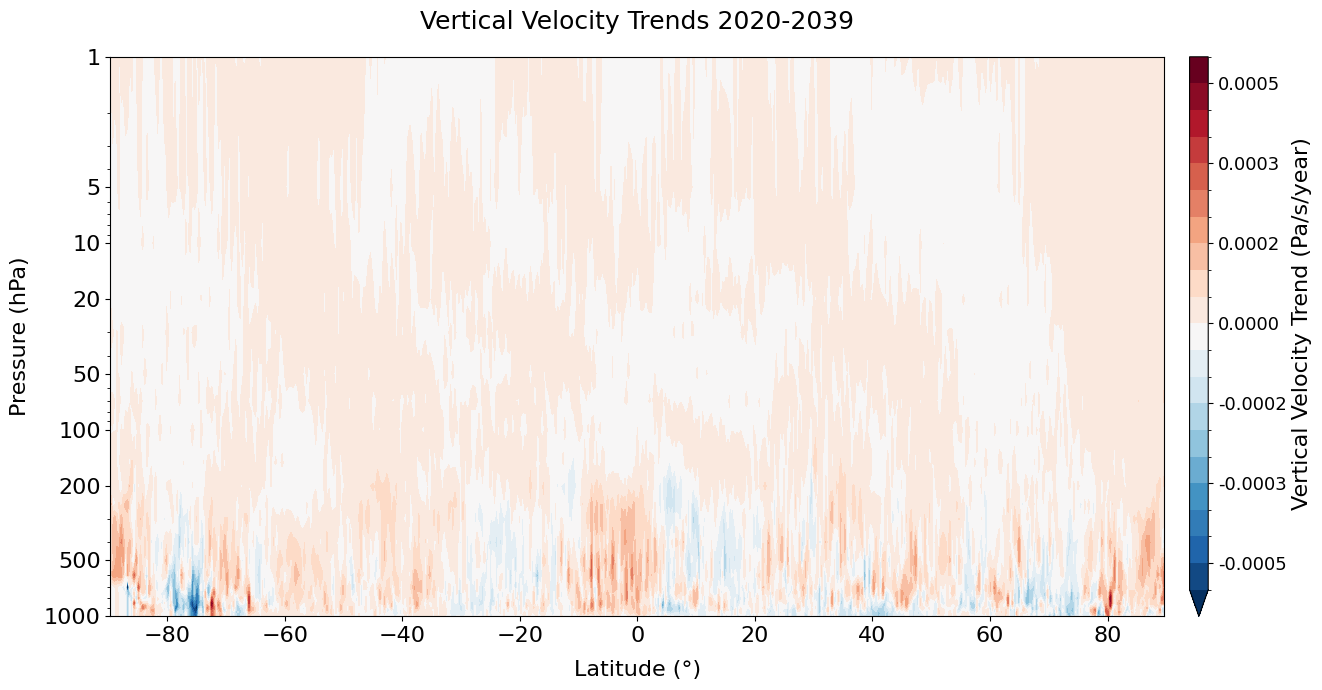

In [29]:
# Create subplot grid for pressure level trends (Temperature)

trend_ds = xr.open_dataset(f"{PROJ2559_DIR}/pl_dy/ana_var_wms/w_velocity_trends_2020-2039.nc")

pressure_levels = trends_ds.isobaricInhPa
n_levels = len(pressure_levels)

import matplotlib.ticker

plt.figure(figsize=(14, 7))

# Create contour levels symmetric around zero
max_trend = np.max(np.abs(trends_ds.w_trend.values))
levels = np.linspace(-max_trend/2, max_trend/2, 21)

# Plot
contour = trends_ds.w_trend.plot.contourf(
    x='lat',
    y='isobaricInhPa',
    levels=levels,
    cmap='RdBu_r',
    add_colorbar=True,
    cbar_kwargs={
        'label': 'Vertical Velocity Trend (Pa/s/year)',
        'orientation': 'vertical',
        'pad': 0.02,
        'aspect': 30
    }
)

# Formatting (identical structure)
plt.yscale('log')
plt.gca().invert_yaxis()
plt.title('Vertical Velocity Trends 2020-2039', pad=20, fontsize=18)
plt.xlabel('Latitude (Â°)', labelpad=10, fontsize=16)
plt.ylabel('Pressure (hPa)', labelpad=10, fontsize=16)

# Tick labels (same formatting)
plt.yticks([1000, 500, 200, 100, 50, 20, 10, 5, 1], 
           ['1000', '500', '200', '100', '50', '20', '10', '5', '1'],
           fontsize=16)
plt.xticks(fontsize=16)

# Colorbar adjustments
cbar = contour.colorbar
cbar.set_label('Vertical Velocity Trend (Pa/s/year)', fontsize=16)
cbar.formatter = matplotlib.ticker.FormatStrFormatter('%.4f')
cbar.ax.tick_params(labelsize=13)

plt.tight_layout()
plt.show()

In [ ]:
    # Positive trends: Increasing downward motion (subsidence)

    # Negative trends: Increasing upward motion


### Next